# Phase 12 Part 1C — Paired Oracle Mechanism Analysis + Visual Evidence

**Model:** Gemini 3.1 Pro High · **Date:** 2026-09-21
**Manifest:** `phase4_v3` · **Taxonomy:** `kub_size_clean_v3_v1` · **Strategy:** SR-1

---

> **READ-ONLY ANALYSIS + VISUALIZATION.** Operates **only** on frozen Phase-12 Part-1B tables.
>
> **No model loading · no inference · no training · no optimizer · no source-table
> modification · no statistics · no winner/rank · no TEST access.**
>
> This is **not** the final Phase-12 supervisor conclusion, **not** a GO/NO-GO decision,
> **not** Phase-13 authorization, and **not** model selection.
>
> **Primary mechanism comparison (the only primary):**
> `GLOBAL_NATIVE` vs `ORACLE_FLOAT_GLOBAL_RETAINED` — paired within the same FULL_FIELD
> case, architecture, native space, GT, and threshold.
>
> Comparators (never primary): `ORACLE_FLOAT_CROP_ONLY` = SECONDARY_HISTORICAL_GEOMETRY_COMPARATOR;
> `ORACLE_LEGACY_UINT8_CROP_ONLY` = COMBINED_LEGACY_RESTORE_SENSITIVITY.


## 2. Scope / Governance

| Rule | Status |
|---|---|
| Model loading | **0** |
| Inference passes | **0** |
| Training epochs / optimizer steps | **0 / 0** |
| Source-table modification | **0** |
| Margin / threshold / geometry changes | **NONE** |
| Statistical testing | **NONE** |
| Winner / rank | **NONE** |
| Final Phase-12 conclusion | **NOT ISSUED** |
| TEST reads | **0** |
| Phase 13 / Phases 14–18 | **NOT STARTED** |

Fixed **non-ranking** model order everywhere: **UNet → Attention U-Net → UNet++ → DeepLabV3+**.


In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display

pd.set_option('display.max_rows', None); pd.set_option('display.max_columns', None)
pd.set_option('display.width', None); pd.set_option('display.max_colwidth', None)
%matplotlib inline

PROJECT_ROOT = Path(r'D:\Softfors\jup')
sys.path.insert(0, str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT/'notebooks'/'phasewise'/'phase_12_oracle_roi'/'code'))
import phase12_oracle_analysis as a

T = a.TABLES; A = a.AUDITS; FIG = a.FIGDIR
ORDER, COLORS = a.ORDER, a.COLORS
print('Fixed model order:', ORDER)
print('Figure directory :', FIG)
print('Module loaded read-only (no model import).')


Fixed model order: ['UNet', 'Attention U-Net', 'UNet++', 'DeepLabV3+']
Figure directory : D:\Softfors\jup\reports\figures\phase12_clean_v3_oracle_analysis
Module loaded read-only (no model import).


## 3. Part-1B Errata

Two non-blocking interpretation corrections. **No accepted artifact was modified.**


In [2]:
err = (A/'phase12_part1b_analysis_errata.md').read_text(encoding='utf-8')
print('\n'.join(err.split('\n')[:10]))
print()
print('CANONICAL LABELS:')
print('  global reproduction gate -> DICE_IOU_GLOBAL_REPRODUCTION_GATE_PASS')
print('  float-vs-legacy          -> COMBINED_LEGACY_RESTORE_SENSITIVITY')


# Phase 12 Part 1B — Analysis Errata / Interpretation Corrections

**Created:** 2026-09-21T01:16:08.055448+00:00 (Phase 12 Part 1C)
**Status:** non-blocking interpretation corrections. **No accepted artifact is modified.**

Both items are **verification-helper / labelling** issues. Neither affects the primary
scientific result. The accepted Part-1B notebook and support code are left untouched.

---


CANONICAL LABELS:
  global reproduction gate -> DICE_IOU_GLOBAL_REPRODUCTION_GATE_PASS
  float-vs-legacy          -> COMBINED_LEGACY_RESTORE_SENSITIVITY


## 4. Frozen Primary Mechanism


In [3]:
fz = json.loads((A/'phase12_clean_v3_oracle_protocol_frozen.json').read_text(encoding='utf-8'))
print('primary variant   :', fz['decisions']['primary_variant']['name'])
print('  formula         :', fz['decisions']['primary_variant']['formula'])
print('  inside union    :', fz['decisions']['primary_variant']['inside_union'])
print('  threshold       :', fz['decisions']['primary_variant']['threshold'], '(after full map)')
print('secondary variant :', fz['decisions']['secondary_variant']['name'])
print('legacy sensitivity:', fz['decisions']['legacy_sensitivity']['variant'])
print('margin            :', fz['decisions']['oracle_geometry']['primary_margin'])
print('reference model   :', fz['decisions']['model_scope']['reference_architecture'])


primary variant   : ORACLE_FLOAT_GLOBAL_RETAINED
  formula         : P(x) = R(x) if U(x) else G(x)
  inside union    : REGIONAL probability (regional REPLACEMENT)
  threshold       : 0.5 (after full map)
secondary variant : ORACLE_FLOAT_CROP_ONLY
legacy sensitivity: ORACLE_LEGACY_UINT8_CROP_ONLY
margin            : 0.25
reference model   : None


## 5. Input Artifact Integrity


In [4]:
integ = a.input_integrity()
for k,v in integ.items(): print(f'  {k}: {v}')
assert integ['case_rows']==1648 and integ['component_rows']==608 and integ['geometry_rows']==152
assert integ['delta_rows']==412 and integ['flag_rows']==103
assert integ['no_many_to_many'], 'component/geometry merge expanded rows'
print()
print('INPUT INTEGRITY - PASS (exact keys, no many-to-many expansion)')


  case_rows: 1648
  case_expected: 1648
  component_rows: 608
  component_expected: 608
  geometry_rows: 152
  geometry_expected: 152
  delta_rows: 412
  delta_expected: 412
  flag_rows: 103
  flag_expected: 103
  geometry_unique_keys: 152
  component_unique_keys: 608
  variants: ['GLOBAL_NATIVE', 'ORACLE_FLOAT_CROP_ONLY', 'ORACLE_FLOAT_GLOBAL_RETAINED', 'ORACLE_LEGACY_UINT8_CROP_ONLY']
  models: ['attention_unet', 'deeplabv3plus', 'unet', 'unetpp']
  strata: {'TINY': 72, 'MEDIUM': 36, 'SMALL': 28, 'LARGE': 16}
  no_many_to_many: True

INPUT INTEGRITY - PASS (exact keys, no many-to-many expansion)


In [5]:
case = a.load_case(); comp = a.load_comp(); geom = a.load_geom()
delta = a.load_delta(); flags = a.load_flags(); sens = a.load_sens()
print('loaded:', len(case), len(comp), len(geom), len(delta), len(flags), len(sens))


loaded:

 1648 608 152 412 103 4


## 6. Primary Global-vs-Oracle Summary


In [6]:
summ = pd.read_csv(T/'phase12_primary_global_vs_oracle_summary.csv')
display(summ[['model','n','global_macro_dice','primary_macro_dice','diff_macro_dice',
              'global_macro_iou','primary_macro_iou','global_macro_precision','primary_macro_precision',
              'global_macro_recall','primary_macro_recall']].round(6))
print()
display(summ[['model','global_object_recall','primary_object_recall',
              'global_empty_predictions','primary_empty_predictions',
              'global_missed_components','primary_missed_components',
              'global_median_valid_hd95','primary_median_valid_hd95']].round(6))
print()
print('No inferential statistics. Raw differences only.')


,model,n,global_macro_dice,primary_macro_dice,diff_macro_dice,global_macro_iou,primary_macro_iou,global_macro_precision,primary_macro_precision,global_macro_recall,primary_macro_recall
0,UNet,103,0.594180,0.724722,0.130542,0.476100,0.586966,0.693919,0.670271,0.653931,0.859321
1,Attention U-Net,103,0.629805,0.699595,0.069790,0.503956,0.559842,0.670962,0.659250,0.701770,0.836333
2,UNet++,103,0.640516,0.726679,0.086164,0.521901,0.587570,0.736065,0.686081,0.658330,0.856491
3,DeepLabV3+,103,0.560251,0.750372,0.190121,0.445751,0.615703,0.708252,0.707868,0.585251,0.863189


,model,global_object_recall,primary_object_recall,global_empty_predictions,primary_empty_predictions,global_missed_components,primary_missed_components,global_median_valid_hd95,primary_median_valid_hd95
0,UNet,0.786408,0.995146,8,0,33,1,44.381609,20.894035
1,Attention U-Net,0.854369,0.995146,3,0,25,1,44.747267,28.001744
2,UNet++,0.839806,0.995146,5,0,27,1,22.980618,20.922398
3,DeepLabV3+,0.762136,1.000000,11,0,38,0,39.492731,17.204651



No inferential statistics. Raw differences only.


## 7. Paired Delta Distribution


In [7]:
dist = pd.read_csv(T/'phase12_primary_delta_distribution_by_model.csv')
display(dist[['model','n','mean_delta_dice','median_delta_dice','q25','q75','min','max',
              'count_improved','count_unchanged','count_worsened',
              'pct_improved','pct_unchanged','pct_worsened']].round(6))
print()
print('Direction is the exact paired sign (positive / zero / negative).')
print('No clinically meaningful cutoff is introduced.')


,model,n,mean_delta_dice,median_delta_dice,q25,q75,min,max,count_improved,count_unchanged,count_worsened,pct_improved,pct_unchanged,pct_worsened
0,UNet,103,0.130542,0.043215,-0.031330,0.208952,-0.276453,0.887926,67,0,36,0.650485,0.0,0.349515
1,Attention U-Net,103,0.069790,0.022539,-0.048740,0.126014,-0.454294,0.833621,59,0,44,0.572816,0.0,0.427184
2,UNet++,103,0.086164,0.018450,-0.041899,0.136539,-0.586567,0.841807,62,0,41,0.601942,0.0,0.398058
3,DeepLabV3+,103,0.190121,0.069951,-0.013692,0.341455,-0.341986,0.859060,74,0,29,0.718447,0.0,0.281553



Direction is the exact paired sign (positive / zero / negative).
No clinically meaningful cutoff is introduced.


## 8. Improved / Worsened Case Counts


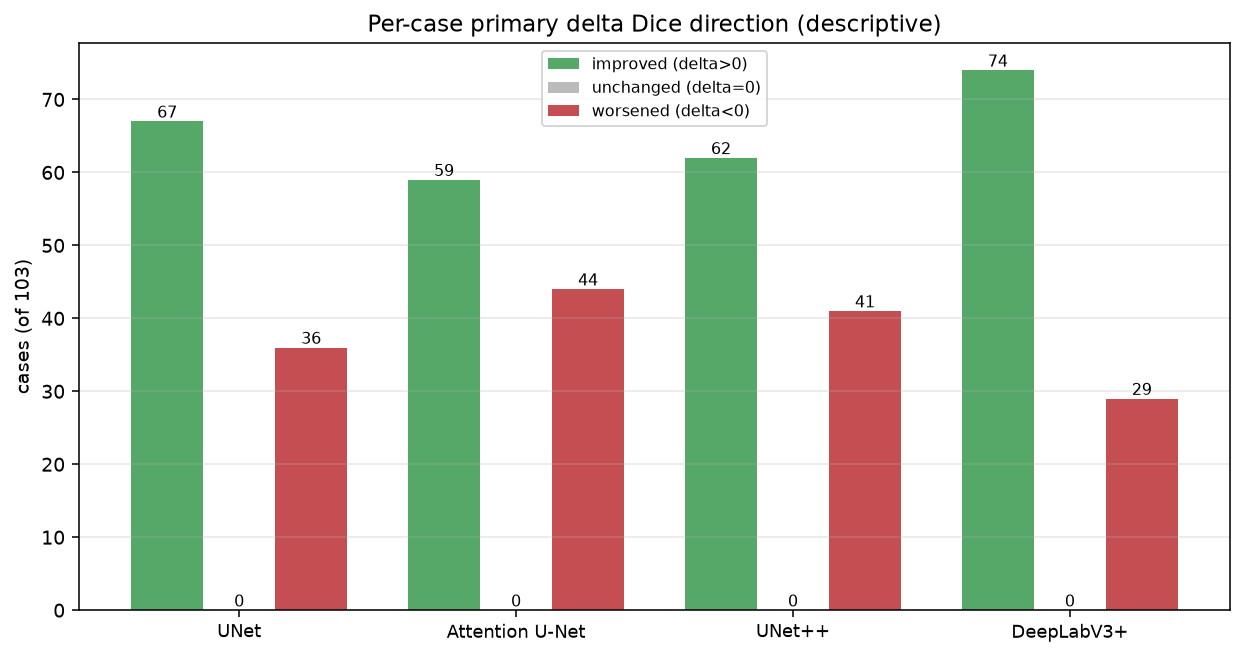

In [8]:
fig, ax = plt.subplots(figsize=(9,4.8))
x = np.arange(len(ORDER)); w=0.26
imp = [int(dist.loc[dist.model==m,'count_improved'].iloc[0]) for m in ORDER]
unc = [int(dist.loc[dist.model==m,'count_unchanged'].iloc[0]) for m in ORDER]
wor = [int(dist.loc[dist.model==m,'count_worsened'].iloc[0]) for m in ORDER]
b1=ax.bar(x-w, imp, w, label='improved (delta>0)', color='#55a868')
b2=ax.bar(x, unc, w, label='unchanged (delta=0)', color='#bbbbbb')
b3=ax.bar(x+w, wor, w, label='worsened (delta<0)', color='#c44e52')
for bs in (b1,b2,b3):
    for b in bs:
        ax.annotate(f'{int(b.get_height())}', (b.get_x()+b.get_width()/2, b.get_height()),
                    ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=9)
ax.set_ylabel('cases (of 103)'); ax.set_title('Per-case primary delta Dice direction (descriptive)')
ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p1=FIG/'delta_direction_counts.png'; fig.savefig(p1, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p1)))


## 9. Benefit / FP-Cost Decomposition


In [9]:
bc = pd.read_csv(T/'phase12_primary_benefit_cost_summary.csv')
display(bc[['model','mean_delta_precision','median_delta_precision','mean_delta_recall','median_delta_recall',
            'mean_delta_fp_pixels','median_delta_fp_pixels','mean_delta_fn_pixels','median_delta_fn_pixels',
            'mean_delta_object_recall','median_delta_object_recall']].round(4))
print()
display(bc[['model','dice_improves_and_fp_increases','dice_improves_and_fp_decreases_or_equal',
            'dice_worsens_and_fp_increases','dice_worsens_and_fp_decreases_or_equal']])
print()
print('Purely descriptive. No value judgement yet.')


,model,mean_delta_precision,median_delta_precision,mean_delta_recall,median_delta_recall,mean_delta_fp_pixels,median_delta_fp_pixels,mean_delta_fn_pixels,median_delta_fn_pixels,mean_delta_object_recall,median_delta_object_recall
0,UNet,-0.0236,-0.0295,0.2054,0.0933,2598.7379,161.0,-1836.2039,-274.0,0.2087,0.0
1,Attention U-Net,-0.0117,-0.0026,0.1346,0.0682,2197.4854,121.0,-1225.1942,-136.0,0.1408,0.0
2,UNet++,-0.0500,-0.0350,0.1982,0.1268,3925.2330,277.0,-2036.4466,-271.0,0.1553,0.0
3,DeepLabV3+,-0.0004,0.0067,0.2779,0.1734,4167.0777,61.0,-2194.2136,-428.0,0.2379,0.0


,model,dice_improves_and_fp_increases,dice_improves_and_fp_decreases_or_equal,dice_worsens_and_fp_increases,dice_worsens_and_fp_decreases_or_equal
0,UNet,45,22,28,8
1,Attention U-Net,33,26,30,14
2,UNet++,48,14,28,13
3,DeepLabV3+,43,31,20,9



Purely descriptive. No value judgement yet.


## 10. Normalized FP / FN Burden


In [10]:
nb = pd.read_csv(T/'phase12_primary_normalized_error_burden.csv')
display(nb[['model','variant','n','fp_per_gt_pixel_mean','fp_per_gt_pixel_median',
            'fn_fraction_mean','fn_fraction_median']].round(6))
print()
print('gt_pixels = TP + FN; fp_per_gt_pixel = FP / gt_pixels; fn_fraction = FN / gt_pixels.')
print('Normalisation removes native-size and target-size dependence. No thresholds created.')


,model,variant,n,fp_per_gt_pixel_mean,fp_per_gt_pixel_median,fn_fraction_mean,fn_fraction_median
0,UNet,GLOBAL,103,0.594976,0.209275,0.346069,0.212028
1,UNet,PRIMARY,103,0.723112,0.412829,0.140679,0.109056
2,Attention U-Net,GLOBAL,103,0.821865,0.259491,0.298230,0.186627
3,Attention U-Net,PRIMARY,103,0.931700,0.434535,0.163667,0.085252
4,UNet++,GLOBAL,103,0.353417,0.178418,0.341670,0.246055
5,UNet++,PRIMARY,103,0.592541,0.409742,0.143509,0.066645
6,DeepLabV3+,GLOBAL,103,0.435047,0.184109,0.414749,0.307238
7,DeepLabV3+,PRIMARY,103,0.602778,0.318065,0.136811,0.107759



gt_pixels = TP + FN; fp_per_gt_pixel = FP / gt_pixels; fn_fraction = FN / gt_pixels.
Normalisation removes native-size and target-size dependence. No thresholds created.


## 11. Exact Component Identity Integrity


In [11]:
m = comp.merge(geom[['sample_id','native_component_id','size_stratum']],
                on=['sample_id','native_component_id'], how='left')
print('geometry unique components :', geom[['sample_id','native_component_id']].drop_duplicates().shape[0])
print('component rows             :', len(comp), '(= 152 x 4)')
print('after merge                :', len(m), '(must be 608)')
print('strata                     :', geom.size_stratum.value_counts().to_dict())
assert len(m)==608 and geom[['sample_id','native_component_id']].drop_duplicates().shape[0]==152
print()
print('COMPONENT IDENTITY INTEGRITY - PASS (exact keys, no expansion)')
print('The Phase-11 case-attributed size approximation is NOT reused.')


geometry unique components : 152
component rows             : 608 (= 152 x 4)
after merge                : 608 (must be 608)
strata                     : {'TINY': 72, 'MEDIUM': 36, 'SMALL': 28, 'LARGE': 16}

COMPONENT IDENTITY INTEGRITY - PASS (exact keys, no expansion)
The Phase-11 case-attributed size approximation is NOT reused.


## 12. Size-Stratified Component Recovery


In [12]:
size = pd.read_csv(T/'phase12_primary_size_stratified_component_recovery.csv')
display(size[['model','size_stratum','gt_components','global_detected','global_missed',
              'global_object_recall','primary_detected','primary_missed','primary_object_recall',
              'recovered_components','lost_components']].round(4))
print()
print('TOTAL recovered:', int(size.recovered_components.sum()),
      '| TOTAL lost detections:', int(size.lost_components.sum()))
print()
print('NOTE: zero lost detections across all strata and models in this dataset.')


,model,size_stratum,gt_components,global_detected,global_missed,global_object_recall,primary_detected,primary_missed,primary_object_recall,recovered_components,lost_components
0,UNet,TINY,72,51,21,0.7083,71,1,0.9861,20,0
1,UNet,SMALL,28,22,6,0.7857,28,0,1.0000,6,0
2,UNet,MEDIUM,36,32,4,0.8889,36,0,1.0000,4,0
3,UNet,LARGE,16,14,2,0.8750,16,0,1.0000,2,0
4,Attention U-Net,TINY,72,56,16,0.7778,71,1,0.9861,15,0
5,Attention U-Net,SMALL,28,24,4,0.8571,28,0,1.0000,4,0
6,Attention U-Net,MEDIUM,36,32,4,0.8889,36,0,1.0000,4,0
7,Attention U-Net,LARGE,16,15,1,0.9375,16,0,1.0000,1,0
8,UNet++,TINY,72,57,15,0.7917,71,1,0.9861,14,0
9,UNet++,SMALL,28,23,5,0.8214,28,0,1.0000,5,0



TOTAL recovered: 120 | TOTAL lost detections: 0

NOTE: zero lost detections across all strata and models in this dataset.


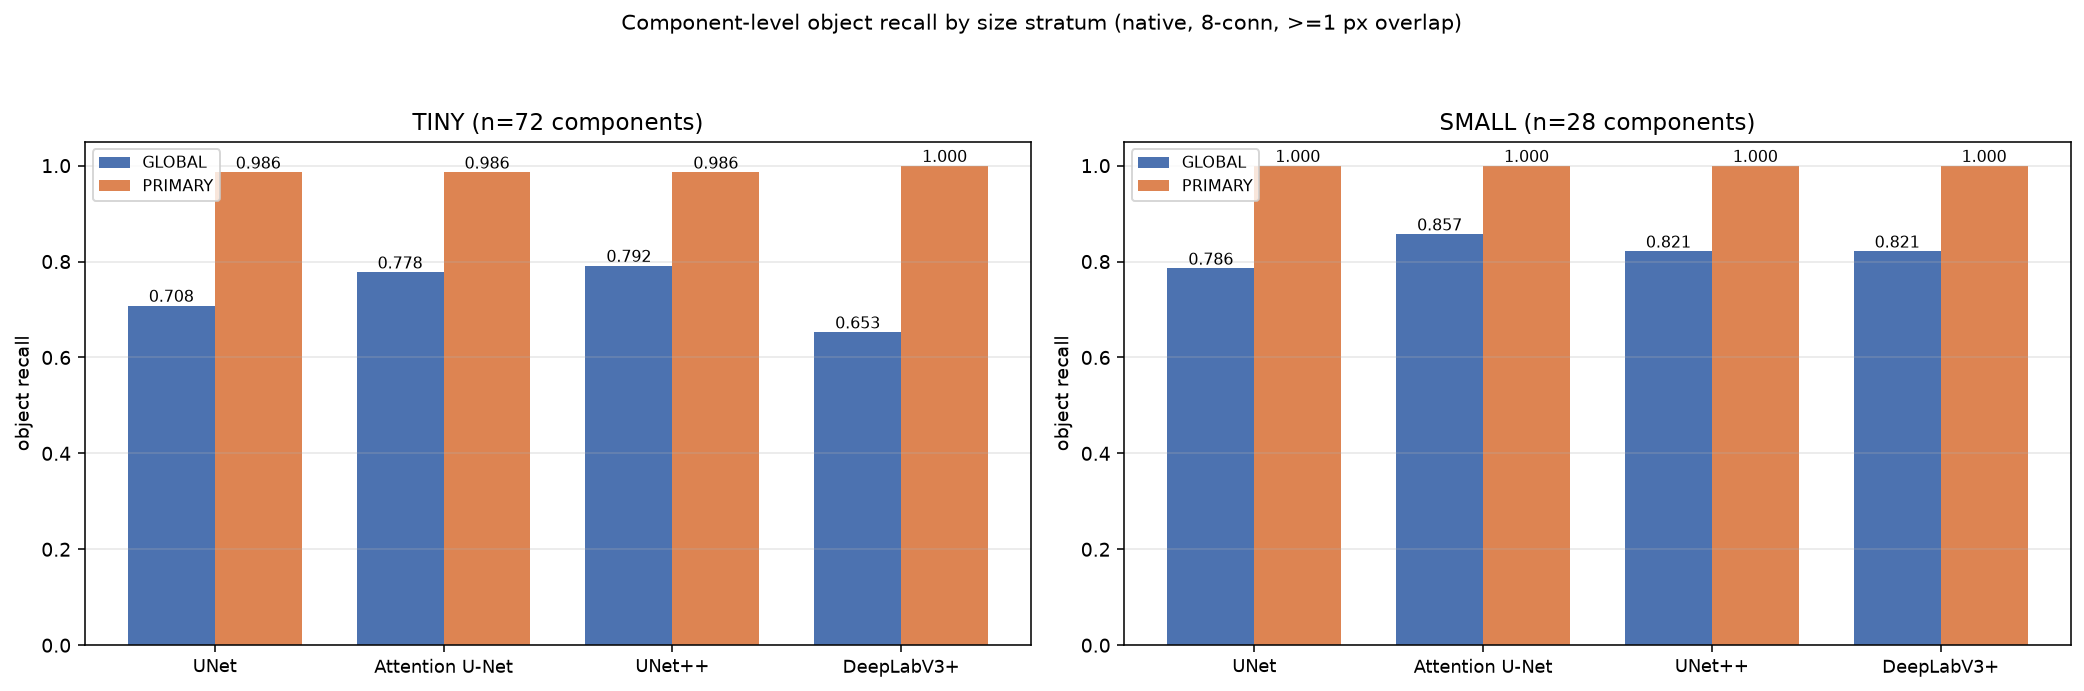

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))
x=np.arange(len(ORDER)); w=0.38
for ax, s, ttl in [(axes[0],'TINY','TINY (n=72 components)'), (axes[1],'SMALL','SMALL (n=28 components)')]:
    d = size[size.size_stratum==s].set_index('model')
    g = [d.loc[m,'global_object_recall'] for m in ORDER]
    p = [d.loc[m,'primary_object_recall'] for m in ORDER]
    b1=ax.bar(x-w/2, g, w, label='GLOBAL', color='#4c72b0')
    b2=ax.bar(x+w/2, p, w, label='PRIMARY', color='#dd8452')
    for bs in (b1,b2):
        for b in bs: ax.annotate(f'{b.get_height():.3f}', (b.get_x()+b.get_width()/2, b.get_height()),
                                 ha='center', va='bottom', fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=9); ax.set_ylim(0,1.05)
    ax.set_ylabel('object recall'); ax.set_title(ttl); ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
fig.suptitle('Component-level object recall by size stratum (native, 8-conn, >=1 px overlap)', fontsize=11)
plt.tight_layout(rect=[0,0,1,0.93]); p2=FIG/'size_stratum_recall.png'; fig.savefig(p2, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p2)))


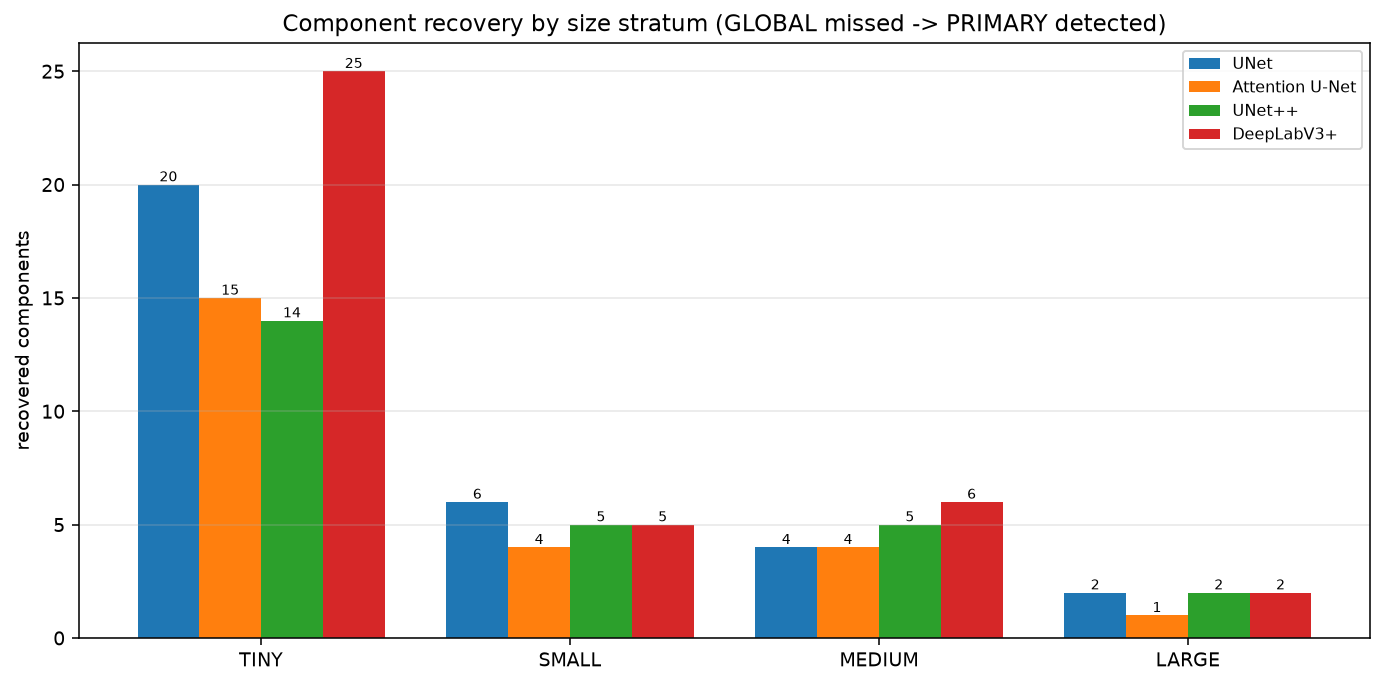

In [14]:
fig, ax = plt.subplots(figsize=(10,5))
x=np.arange(len(a.STRATA)); w=0.2
for i,mdl in enumerate(ORDER):
    d = size[size.model==mdl].set_index('size_stratum')
    vals=[d.loc[s,'recovered_components'] if s in d.index else 0 for s in a.STRATA]
    b=ax.bar(x+(i-1.5)*w, vals, w, label=mdl, color=COLORS[mdl])
    for bb in b: ax.annotate(f'{int(bb.get_height())}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                             ha='center', va='bottom', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(a.STRATA)
ax.set_ylabel('recovered components'); ax.set_title('Component recovery by size stratum (GLOBAL missed -> PRIMARY detected)')
ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p3=FIG/'component_recovery_by_stratum.png'; fig.savefig(p3, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p3)))


## 13. Multi-Component Transitions


In [15]:
mc = pd.read_csv(T/'phase12_primary_multicomponent_outcomes.csv')
display(mc)
tr = pd.read_csv(T/'phase12_primary_multicomponent_transitions.csv')
print()
print('transition counts (all models pooled):')
print(tr['transition'].value_counts().to_string())
print()
print('No inferential testing.')


,model,model_key,multicomponent_cases,global_complete,global_partial,global_miss,primary_complete,primary_partial,primary_miss
0,UNet,unet,49,30,16,3,48,1,0
1,Attention U-Net,attention_unet,49,33,12,4,48,1,0
2,UNet++,unetpp,49,33,11,5,48,1,0
3,DeepLabV3+,deeplabv3plus,49,27,17,5,49,0,0



transition counts (all models pooled):
transition
COMPLETE_DETECTION -> COMPLETE_DETECTION    123
PARTIAL_DETECTION -> COMPLETE_DETECTION      53
COMPLETE_MISS -> COMPLETE_DETECTION          17
PARTIAL_DETECTION -> PARTIAL_DETECTION        3

No inferential testing.


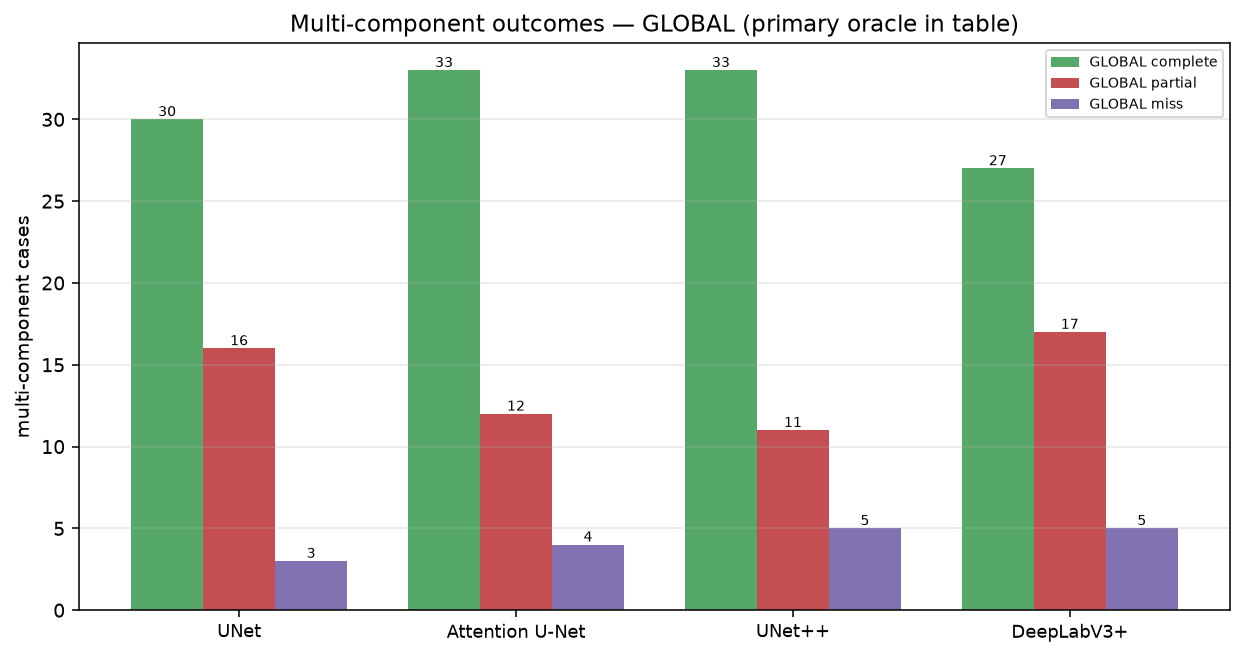

In [16]:
fig, ax = plt.subplots(figsize=(9,4.8))
x=np.arange(len(ORDER)); w=0.26
for i,c in enumerate(['global_complete','global_partial','global_miss']):
    b=ax.bar(x+(i-1)*w, mc[c], w, label=c.replace('global_','GLOBAL '), color=['#55a868','#c44e52','#8172b2'][i])
    for bb in b: ax.annotate(f'{int(bb.get_height())}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                             ha='center', va='bottom', fontsize=7)
ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=9)
ax.set_ylabel('multi-component cases'); ax.set_title('Multi-component outcomes — GLOBAL (primary oracle in table)')
ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p4=FIG/'multicomponent_outcomes.png'; fig.savefig(p4, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p4)))


## 14. Empty-Prediction Recovery


In [17]:
emp = pd.read_csv(T/'phase12_primary_empty_prediction_recovery.csv')
display(emp[['model','global_empty','primary_empty','recovered_empty_cases','new_empty_cases']])
print()
for _,r in emp.iterrows():
    if r['recovered_sample_ids']:
        print(f"{r['model']}: recovered {r['recovered_empty_cases']} -> {r['recovered_sample_ids']}")
print()
print('exact sample IDs also persisted in phase12_primary_empty_prediction_ids.csv')


,model,global_empty,primary_empty,recovered_empty_cases,new_empty_cases
0,UNet,8,0,8,0
1,Attention U-Net,3,0,3,0
2,UNet++,5,0,5,0
3,DeepLabV3+,11,0,11,0



UNet: recovered 8 -> 416e6f7d9e35c6bf4bde51e191a7e92d;5dd4436a2065b8855ce1dfbed228bce7;66b947d8ead11ae1260bc3142ca1707d;717a1ec0a082fae24e2341341ca83e77;8499adc2a4821269c65d3562cd528774;a626dd389032147c7d4ebd2b1db39e45;ad4af1ce1b3dde6ad04fa095aacd92f5;d1105b983f55fdf1ffd56d72c3bcef2d
Attention U-Net: recovered 3 -> ad4af1ce1b3dde6ad04fa095aacd92f5;b0473630de9211114c94c7dc0363ebd9;e1e165d69d6844c8a599786d865cdd21
UNet++: recovered 5 -> 416e6f7d9e35c6bf4bde51e191a7e92d;5dd4436a2065b8855ce1dfbed228bce7;8c8d2107815002b7913bd6a42f93b394;ad4af1ce1b3dde6ad04fa095aacd92f5;b0473630de9211114c94c7dc0363ebd9
DeepLabV3+: recovered 11 -> 15c6b69254f60701d181da403d8c2906;1ba084b5439ffee651b4f5e0697e2209;3a60721211529da5e0672ceedace34e1;416e6f7d9e35c6bf4bde51e191a7e92d;5dd4436a2065b8855ce1dfbed228bce7;9612ae24d2d643dc2c68e9d86747caeb;a0883cebccde3437bdd58de610d05b4e;ad4af1ce1b3dde6ad04fa095aacd92f5;b0473630de9211114c94c7dc0363ebd9;b9c83c40ec013198ea1355ef26cd6bdb;f860cbfe7c79e5772795a64bac5de7e7

exa

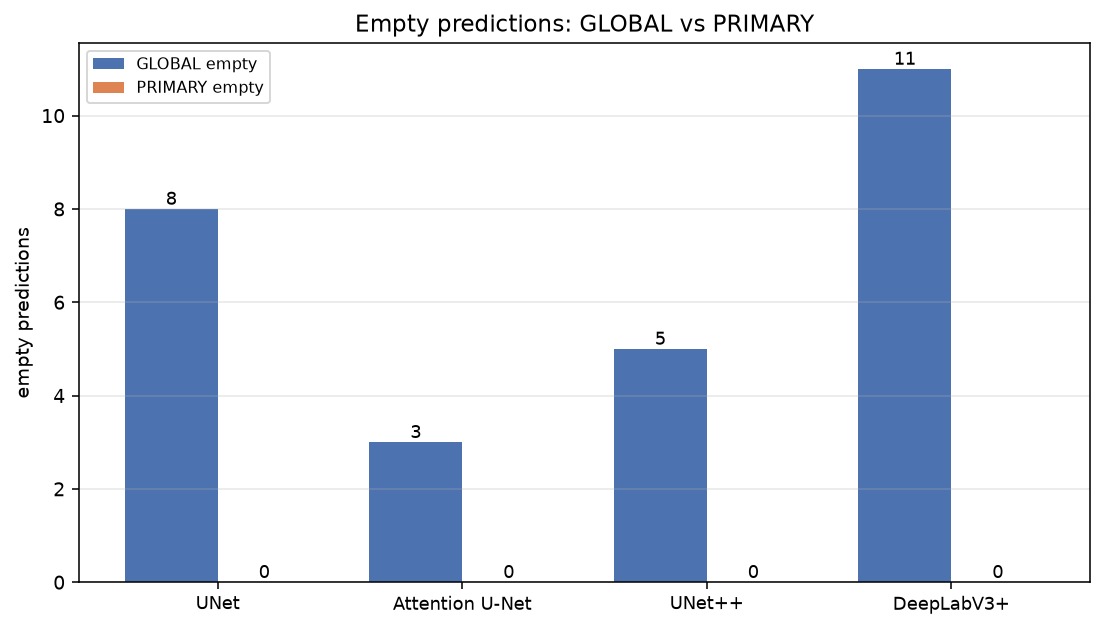

In [18]:
fig, ax = plt.subplots(figsize=(8,4.6))
x=np.arange(len(ORDER)); w=0.38
b1=ax.bar(x-w/2, emp['global_empty'], w, label='GLOBAL empty', color='#4c72b0')
b2=ax.bar(x+w/2, emp['primary_empty'], w, label='PRIMARY empty', color='#dd8452')
for bs in (b1,b2):
    for b in bs: ax.annotate(f'{int(b.get_height())}', (b.get_x()+b.get_width()/2, b.get_height()),
                             ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=9)
ax.set_ylabel('empty predictions'); ax.set_title('Empty predictions: GLOBAL vs PRIMARY')
ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p5=FIG/'empty_prediction_recovery.png'; fig.savefig(p5, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p5)))


## 15. HD95 Validity / Boundary Analysis


In [19]:
hd = pd.read_csv(T/'phase12_primary_hd95_analysis.csv')
display(hd[['model','global_valid_n','global_invalid_n','primary_valid_n','primary_invalid_n',
            'both_valid_paired_n','median_valid_hd95_global','median_valid_hd95_primary',
            'delta_hd95_mean','delta_hd95_median','delta_hd95_q25','delta_hd95_q75']].round(4))
print()
print('Negative delta_hd95 = lower boundary distance. Invalid HD95 flagged, never dropped.')


,model,global_valid_n,global_invalid_n,primary_valid_n,primary_invalid_n,both_valid_paired_n,median_valid_hd95_global,median_valid_hd95_primary,delta_hd95_mean,delta_hd95_median,delta_hd95_q25,delta_hd95_q75
0,UNet,95,8,103,0,95,44.3816,31.6228,-57.1157,-1.1233,-5.7452,1.0278
1,Attention U-Net,100,3,103,0,100,44.7473,32.2195,-40.1473,-1.1095,-5.8923,0.9030
2,UNet++,98,5,103,0,98,22.9806,23.1804,-75.1212,-0.9425,-4.8940,2.4749
3,DeepLabV3+,92,11,103,0,92,39.4927,25.8454,-56.3340,-0.8375,-6.0399,0.5957



Negative delta_hd95 = lower boundary distance. Invalid HD95 flagged, never dropped.


## 16. Phase-11 Frozen Cohort Bridge


In [20]:
coh = pd.read_csv(T/'phase12_phase11_frozen_cohort_oracle_response.csv')
display(coh[['cohort','model','n_cases','n_case_model_rows','global_mean_dice','primary_mean_dice',
             'mean_delta_dice','median_delta_dice','global_object_recall','primary_object_recall',
             'recovered_components','empty_recoveries']].round(4))
print()
print('n_cases = distinct FULL_FIELD cases; n_case_model_rows = cases x 1 model. NOT mixed.')
print('Cohorts are pre-frozen; NOT reselected after seeing results.')


,cohort,model,n_cases,n_case_model_rows,global_mean_dice,primary_mean_dice,mean_delta_dice,median_delta_dice,global_object_recall,primary_object_recall,recovered_components,empty_recoveries
0,ALL_FOUR_LOW,UNet,12,12,0.0817,0.5903,0.5086,0.6035,0.2500,1.0000,13,4
1,ALL_FOUR_LOW,Attention U-Net,12,12,0.1180,0.4848,0.3667,0.3477,0.3333,1.0000,11,2
2,ALL_FOUR_LOW,UNet++,12,12,0.1012,0.6092,0.5080,0.6173,0.2917,1.0000,13,5
3,ALL_FOUR_LOW,DeepLabV3+,12,12,0.0957,0.6552,0.5594,0.6713,0.3750,1.0000,10,5
4,PHASE11_HARD_CASE,UNet,10,10,0.2106,0.6526,0.4420,0.5022,0.3000,1.0000,11,3
5,PHASE11_HARD_CASE,Attention U-Net,10,10,0.1844,0.5669,0.3825,0.3276,0.3000,1.0000,11,1
6,PHASE11_HARD_CASE,UNet++,10,10,0.0583,0.6797,0.6214,0.6995,0.1000,1.0000,14,4
7,PHASE11_HARD_CASE,DeepLabV3+,10,10,0.1716,0.7049,0.5334,0.6236,0.4000,1.0000,9,3
8,PHASE11_TOP_DISAGREEMENT,UNet,4,4,0.1378,0.7920,0.6542,0.7812,0.2500,1.0000,3,2
9,PHASE11_TOP_DISAGREEMENT,Attention U-Net,4,4,0.7701,0.7947,0.0246,0.0148,1.0000,1.0000,0,0



n_cases = distinct FULL_FIELD cases; n_case_model_rows = cases x 1 model. NOT mixed.
Cohorts are pre-frozen; NOT reselected after seeing results.


## 17. ALL_FOUR_LOW Analysis


In [21]:
afl = pd.read_csv(T/'phase12_all_four_low_oracle_response.csv')
display(afl[['sample_id','model','category','native_gt_components','global_dice','primary_dice',
             'delta_dice','global_object_recall','primary_object_recall','recovered_components']].round(4))
print()
print('per-model mean delta Dice on the 12 ALL_FOUR_LOW cases:')
print(afl.groupby('model')['delta_dice'].mean().round(4).to_string())
print()
print('Central to the hypothesis that some failures reflect resolution/scale rather than one')
print('architecture. No causal claim.')


,sample_id,model,category,native_gt_components,global_dice,primary_dice,delta_dice,global_object_recall,primary_object_recall,recovered_components
0,1e08d0c4a0448b41b2dbb61a1160c203,UNet,Bladder_Stone,2,0.4610,0.5318,0.0708,1.0,1.0,0
1,1e08d0c4a0448b41b2dbb61a1160c203,Attention U-Net,Bladder_Stone,2,0.5031,0.5209,0.0178,1.0,1.0,0
2,1e08d0c4a0448b41b2dbb61a1160c203,UNet++,Bladder_Stone,2,0.5367,0.5300,-0.0066,1.0,1.0,0
3,1e08d0c4a0448b41b2dbb61a1160c203,DeepLabV3+,Bladder_Stone,2,0.3645,0.4175,0.0529,1.0,1.0,0
4,3a60721211529da5e0672ceedace34e1,UNet,Bladder_Stone,1,0.0000,0.4885,0.4885,0.0,1.0,1
5,3a60721211529da5e0672ceedace34e1,Attention U-Net,Bladder_Stone,1,0.0000,0.3085,0.3085,0.0,1.0,1
6,3a60721211529da5e0672ceedace34e1,UNet++,Bladder_Stone,1,0.4693,0.5223,0.0530,1.0,1.0,0
7,3a60721211529da5e0672ceedace34e1,DeepLabV3+,Bladder_Stone,1,0.0000,0.8296,0.8296,0.0,1.0,1
8,416e6f7d9e35c6bf4bde51e191a7e92d,UNet,Ureteric_Stone,2,0.0000,0.7175,0.7175,0.0,1.0,2
9,416e6f7d9e35c6bf4bde51e191a7e92d,Attention U-Net,Ureteric_Stone,2,0.3942,0.6624,0.2683,0.5,1.0,1



per-model mean delta Dice on the 12 ALL_FOUR_LOW cases:
model
Attention U-Net    0.3667
DeepLabV3+         0.5594
UNet               0.5086
UNet++             0.5080

Central to the hypothesis that some failures reflect resolution/scale rather than one
architecture. No causal claim.


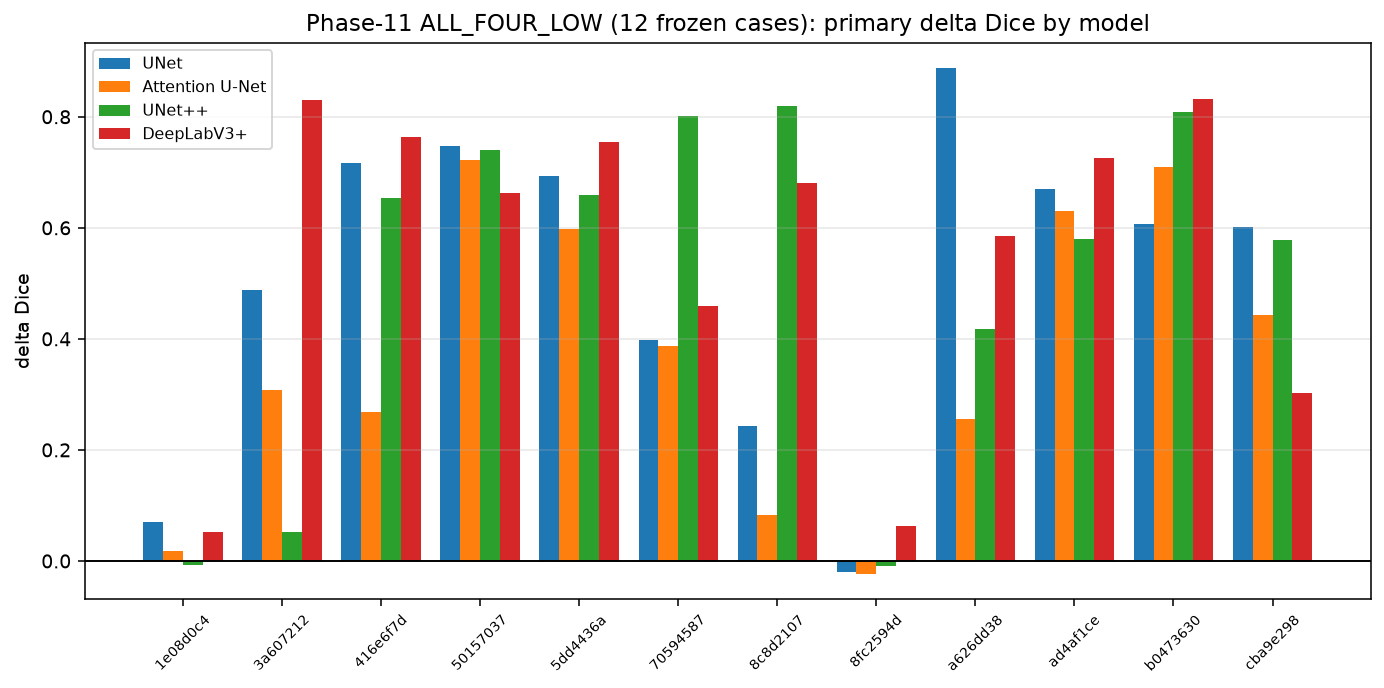

In [22]:
fig, ax = plt.subplots(figsize=(10,5))
piv = afl.pivot_table(index='sample_id', columns='model', values='delta_dice')
x=np.arange(len(piv)); w=0.2
for i,mdl in enumerate(ORDER):
    vals = piv[mdl].values if mdl in piv.columns else [0]*len(piv)
    ax.bar(x+(i-1.5)*w, vals, w, label=mdl, color=COLORS[mdl])
ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x); ax.set_xticklabels([s[:8] for s in piv.index], fontsize=7, rotation=45)
ax.set_ylabel('delta Dice'); ax.set_title('Phase-11 ALL_FOUR_LOW (12 frozen cases): primary delta Dice by model')
ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p6=FIG/'all_four_low_response.png'; fig.savefig(p6, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p6)))


## 18. Category Metadata Analysis


In [23]:
cat = pd.read_csv(T/'phase12_primary_category_analysis.csv')
display(cat[['model','category','n','global_mean_dice','primary_mean_dice',
             'mean_delta_dice','median_delta_dice','improved','worsened']].round(4))
print()
print('Bladder/Kidney/Ureteric are subgroup METADATA, not segmentation classes.')
print('Ureteric n is small - do not overinterpret.')


,model,category,n,global_mean_dice,primary_mean_dice,mean_delta_dice,median_delta_dice,improved,worsened
0,UNet,Bladder_Stone,55,0.5653,0.7338,0.1685,0.0569,45,10
1,UNet,Kidney_Stone,44,0.6534,0.7282,0.0748,-0.0087,19,25
2,UNet,Ureteric_Stone,4,0.3403,0.5612,0.2209,0.1362,3,1
3,Attention U-Net,Bladder_Stone,55,0.5935,0.6875,0.0940,0.0420,39,16
4,Attention U-Net,Kidney_Stone,44,0.6773,0.7134,0.0362,-0.0241,17,27
5,Attention U-Net,Ureteric_Stone,4,0.6069,0.7137,0.1068,0.1627,3,1
6,UNet++,Bladder_Stone,55,0.6302,0.7399,0.1097,0.0402,41,14
7,UNet++,Kidney_Stone,44,0.6625,0.7119,0.0494,-0.0261,18,26
8,UNet++,Ureteric_Stone,4,0.5409,0.7083,0.1674,0.1298,3,1
9,DeepLabV3+,Bladder_Stone,55,0.5174,0.7638,0.2464,0.1286,47,8



Bladder/Kidney/Ureteric are subgroup METADATA, not segmentation classes.
Ureteric n is small - do not overinterpret.


## 19. Cross-Architecture Consistency


In [24]:
cad = pd.read_csv(T/'phase12_cross_architecture_distribution.csv')
piv = cad.pivot_table(index='n_models', columns='metric', values='n_cases').fillna(0).astype(int)
display(piv)
ca = pd.read_csv(T/'phase12_cross_architecture_oracle_consistency.csv')
print()
print('cases with all four models positive delta Dice:', int(ca.all_four_delta_positive.sum()), 'of', len(ca))
print('cases with all four models object-recall non-worse:', int(ca.all_four_object_recall_nonworse.sum()), 'of', len(ca))
print()
print('No arbitrary generality threshold.')


metric,models_component_recovery_positive,models_delta_positive,models_object_recall_improved
n_models,,,
0,62,17,62
1,16,18,16
2,3,6,3
3,7,16,7
4,15,46,15



cases with all four models positive delta Dice: 46 of 103
cases with all four models object-recall non-worse: 103 of 103

No arbitrary generality threshold.


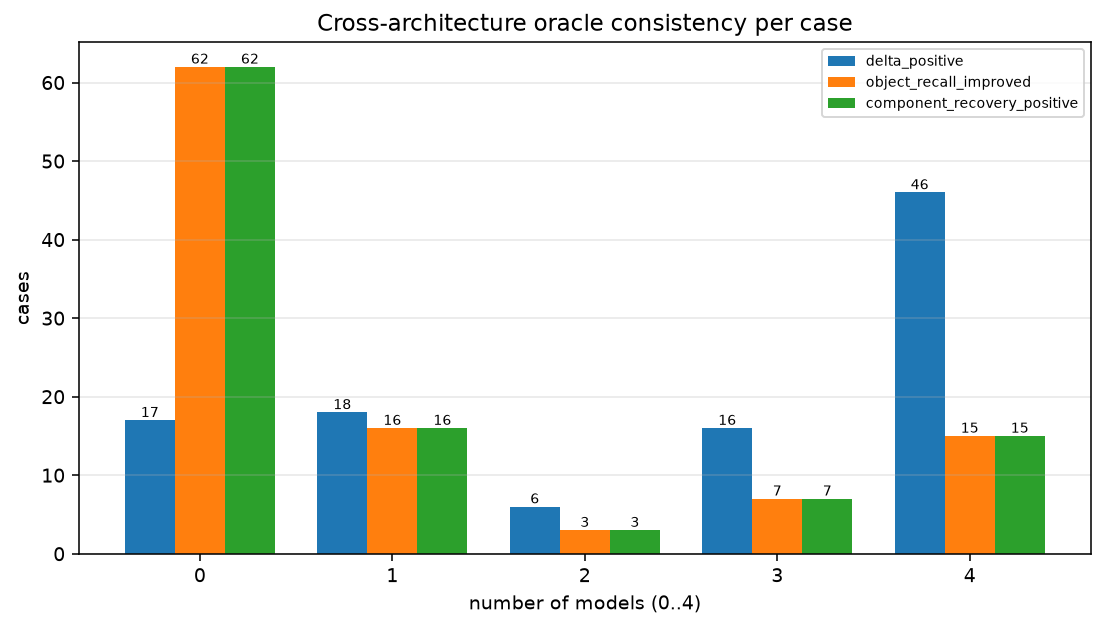

In [25]:
fig, ax = plt.subplots(figsize=(8,4.6))
x=np.arange(5); w=0.26
for i,metric in enumerate(['models_delta_positive','models_object_recall_improved',
                           'models_component_recovery_positive']):
    vals=[int(cad[(cad.metric==metric)&(cad.n_models==i)].n_cases.iloc[0]) for i in range(5)]
    b=ax.bar(x+(i-1)*w, vals, w, label=metric.replace('models_',''))
    for bb in b: ax.annotate(f'{int(bb.get_height())}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                             ha='center', va='bottom', fontsize=7)
ax.set_xticks(x); ax.set_xlabel('number of models (0..4)'); ax.set_ylabel('cases')
ax.set_title('Cross-architecture oracle consistency per case'); ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p7=FIG/'cross_architecture_consistency.png'; fig.savefig(p7, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p7)))


## 20. Primary vs Crop-Only Comparator

**Crop-only includes oracle background suppression; it is NOT the primary SR-1 mechanism
estimate.**


In [26]:
crop = pd.read_csv(T/'phase12_primary_vs_crop_only_comparator.csv')
display(crop[['model','primary_macro_dice','crop_only_macro_dice',
              'macro_dice_difference_crop_minus_primary','macro_precision_difference',
              'macro_recall_difference','mean_fp_difference','mean_fn_difference',
              'object_recall_difference','interpretation']].round(4))
print()
print('Crop-only zeroes all prediction outside oracle crop support, i.e. it has access to')
print('oracle background suppression. It must NOT be called preferred.')


,model,primary_macro_dice,crop_only_macro_dice,macro_dice_difference_crop_minus_primary,macro_precision_difference,macro_recall_difference,mean_fp_difference,mean_fn_difference,object_recall_difference,interpretation
0,UNet,0.7247,0.7932,0.0685,0.0979,0.0,-584.1748,0.0,0.0,ORACLE_BACKGROUND_SUPPRESSION_ADVANTAGE_PRESENT
1,Attention U-Net,0.6996,0.7736,0.0740,0.1102,0.0,-655.3786,0.0,0.0,ORACLE_BACKGROUND_SUPPRESSION_ADVANTAGE_PRESENT
2,UNet++,0.7267,0.7730,0.0464,0.0739,0.0,-362.0583,0.0,0.0,ORACLE_BACKGROUND_SUPPRESSION_ADVANTAGE_PRESENT
3,DeepLabV3+,0.7504,0.7979,0.0475,0.0761,0.0,-405.3398,0.0,0.0,ORACLE_BACKGROUND_SUPPRESSION_ADVANTAGE_PRESENT



Crop-only zeroes all prediction outside oracle crop support, i.e. it has access to
oracle background suppression. It must NOT be called preferred.


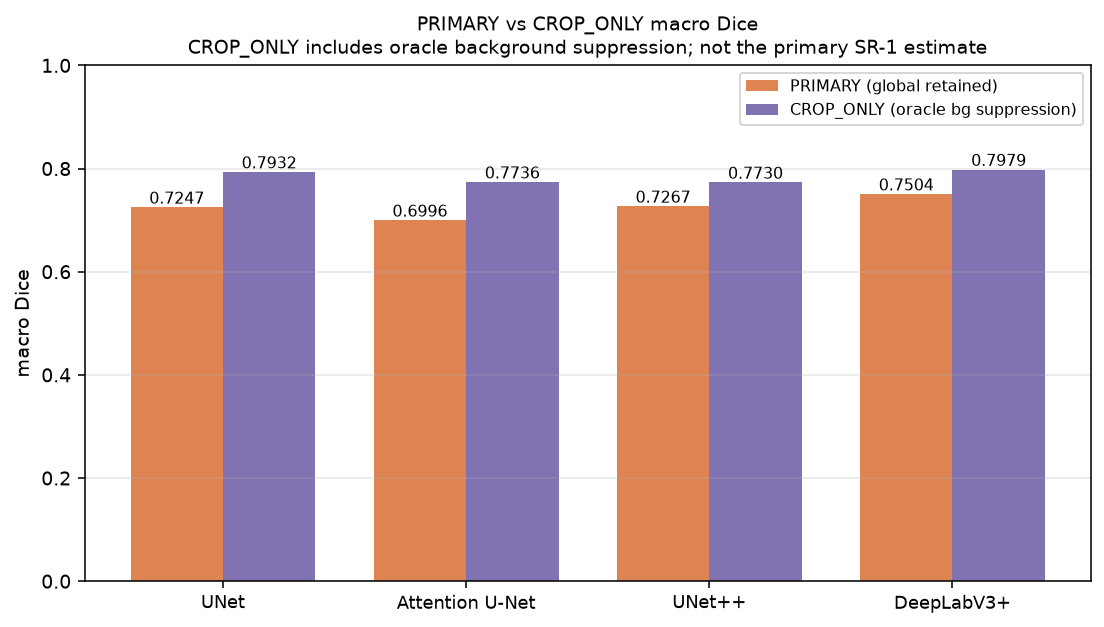

In [27]:
fig, ax = plt.subplots(figsize=(8,4.6))
x=np.arange(len(ORDER)); w=0.38
b1=ax.bar(x-w/2, crop['primary_macro_dice'], w, label='PRIMARY (global retained)', color='#dd8452')
b2=ax.bar(x+w/2, crop['crop_only_macro_dice'], w, label='CROP_ONLY (oracle bg suppression)', color='#8172b2')
for bs in (b1,b2):
    for b in bs: ax.annotate(f'{b.get_height():.4f}', (b.get_x()+b.get_width()/2, b.get_height()),
                             ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=9); ax.set_ylim(0,1.0)
ax.set_ylabel('macro Dice')
ax.set_title('PRIMARY vs CROP_ONLY macro Dice\nCROP_ONLY includes oracle background suppression; not the primary SR-1 estimate',
             fontsize=10)
ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p8=FIG/'primary_vs_crop_only.png'; fig.savefig(p8, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p8)))


## 21. Combined Legacy Restore Sensitivity


In [28]:
display(sens[['model','n_cases','mean_abs_dice_diff','max_abs_dice_diff',
                'mean_abs_iou_diff','max_abs_iou_diff']].round(6))
print()
print('CANONICAL LABEL: COMBINED_LEGACY_RESTORE_SENSITIVITY')
print('Cannot isolate uint8 quantisation alone: the restoration engine also differs')
print('  FLOAT  : Torch bilinear, align_corners=False')
print('  LEGACY : PIL bilinear + uint8 quantisation')
print()
print('MUST NOT be used in the regional-integration gate. No rerun performed.')


,model,n_cases,mean_abs_dice_diff,max_abs_dice_diff,mean_abs_iou_diff,max_abs_iou_diff
0,Attention U-Net,103,0.002683,0.013700,0.003510,0.013885
1,DeepLabV3+,103,0.000863,0.005205,0.001220,0.007727
2,UNet,103,0.002828,0.018519,0.003884,0.027212
3,UNet++,103,0.002256,0.017554,0.002936,0.018293



CANONICAL LABEL: COMBINED_LEGACY_RESTORE_SENSITIVITY
Cannot isolate uint8 quantisation alone: the restoration engine also differs
  FLOAT  : Torch bilinear, align_corners=False
  LEGACY : PIL bilinear + uint8 quantisation

MUST NOT be used in the regional-integration gate. No rerun performed.


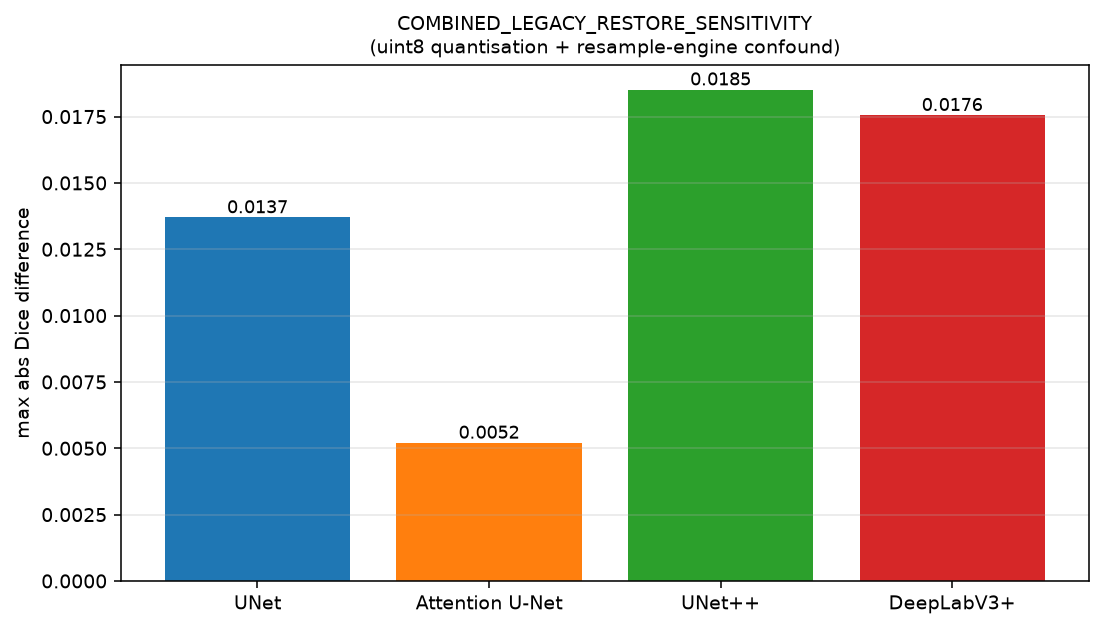

In [29]:
fig, ax = plt.subplots(figsize=(8,4.6))
b=ax.bar(ORDER, sens['max_abs_dice_diff'], color=[COLORS[m] for m in ORDER])
for bb in b: ax.annotate(f'{bb.get_height():.4f}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                         ha='center', va='bottom', fontsize=9)
ax.set_ylabel('max abs Dice difference')
ax.set_title('COMBINED_LEGACY_RESTORE_SENSITIVITY\n(uint8 quantisation + resample-engine confound)', fontsize=10)
ax.grid(True, alpha=.3, axis='y')
plt.tight_layout(); p9=FIG/'combined_legacy_restore_sensitivity.png'; fig.savefig(p9, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p9)))


## 22. Visual Comparison Dashboard


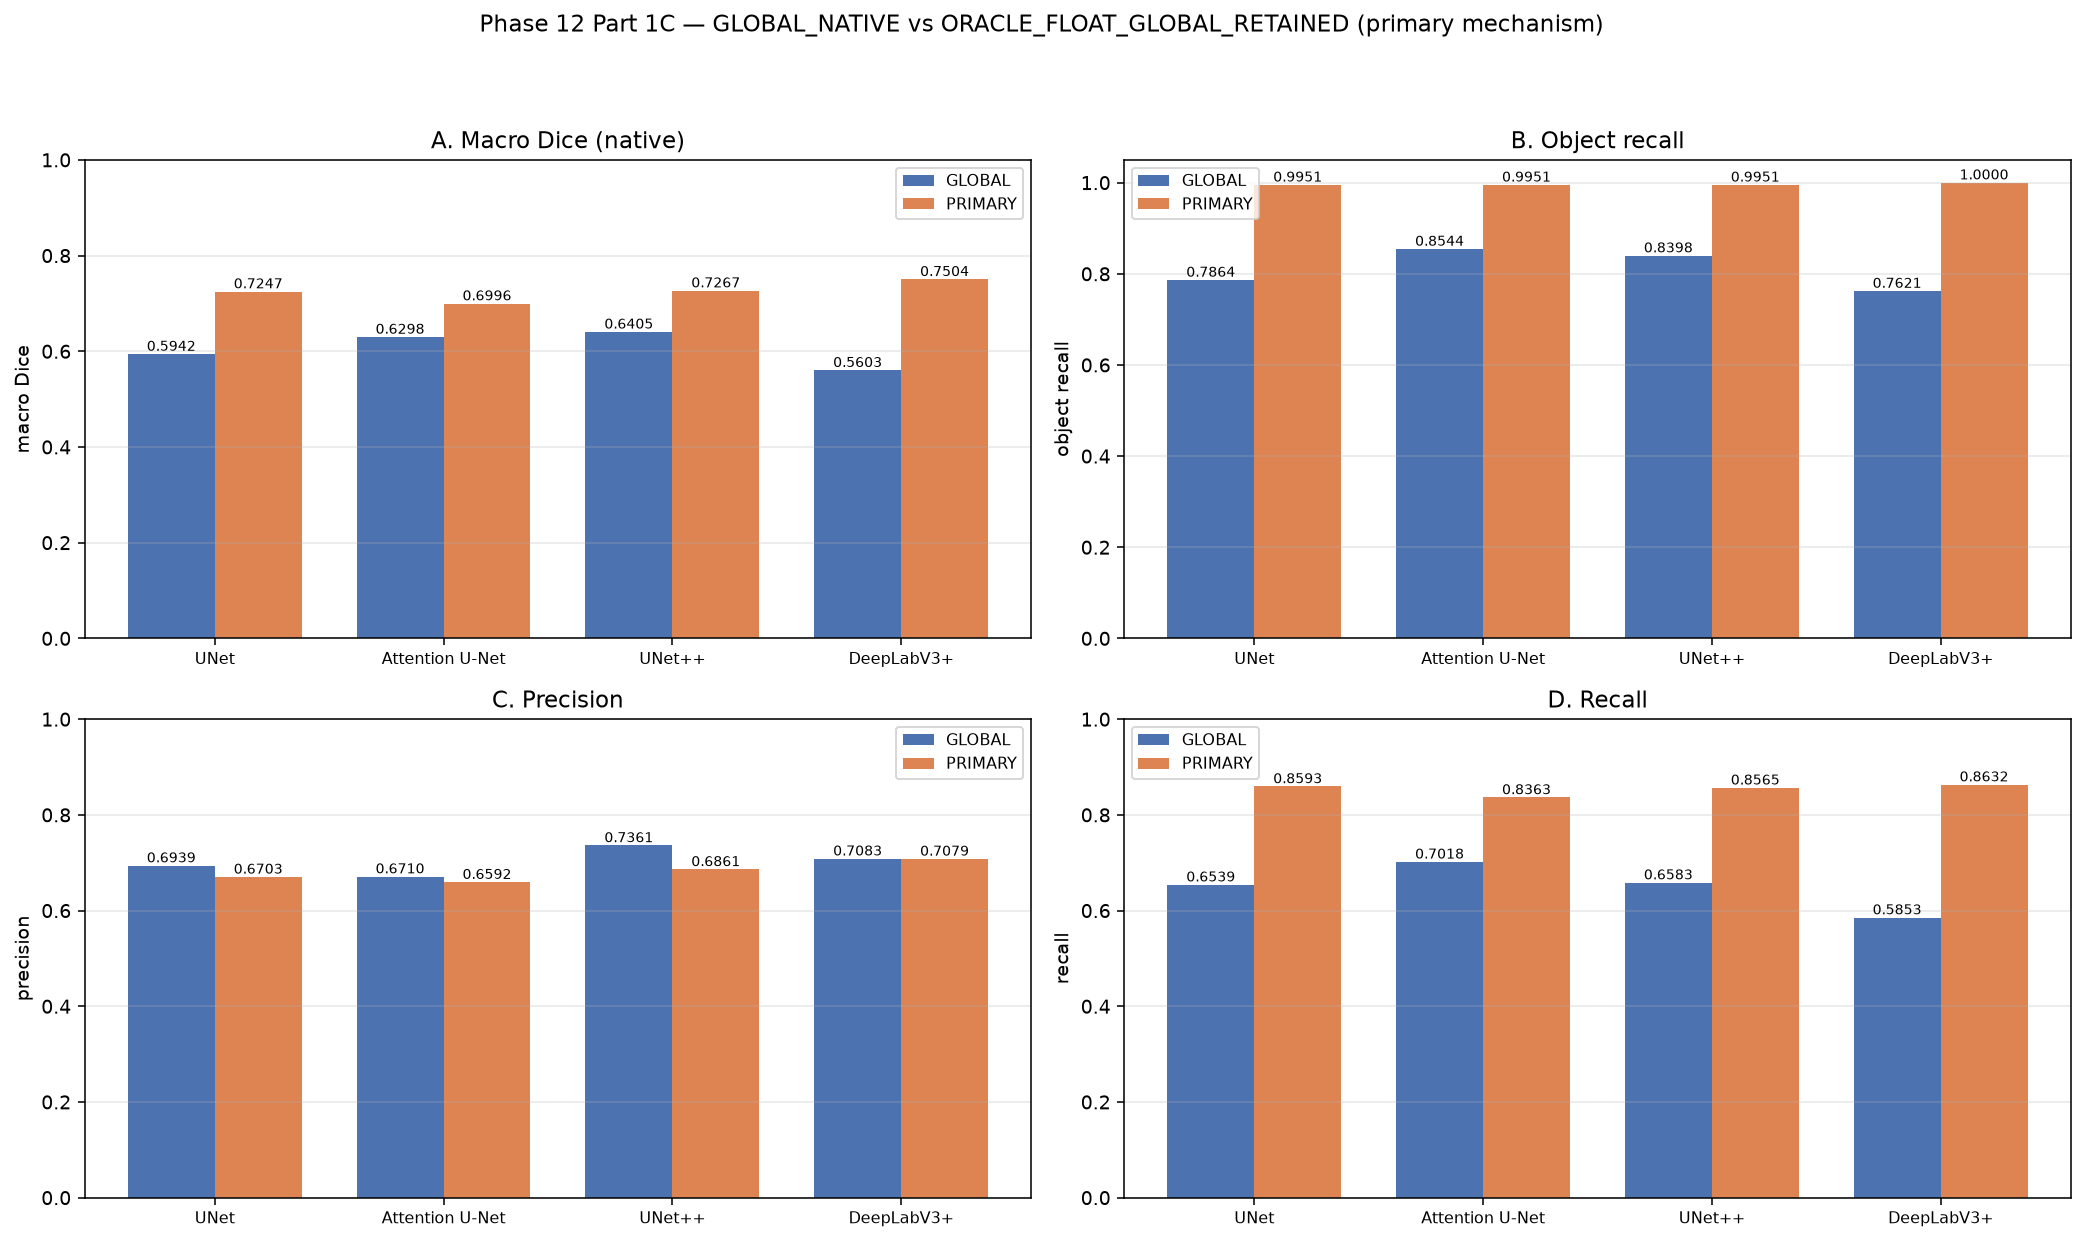

In [30]:
fig, axes = plt.subplots(2, 2, figsize=(15,9))
x=np.arange(len(ORDER)); w=0.38
def paired(ax, gcol, pcol, ylabel, title, ylim=None):
    b1=ax.bar(x-w/2, summ[gcol], w, label='GLOBAL', color='#4c72b0')
    b2=ax.bar(x+w/2, summ[pcol], w, label='PRIMARY', color='#dd8452')
    for bs in (b1,b2):
        for b in bs: ax.annotate(f'{b.get_height():.4f}', (b.get_x()+b.get_width()/2, b.get_height()),
                                 ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=8)
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend(fontsize=8); ax.grid(True, alpha=.3, axis='y')
    if ylim: ax.set_ylim(*ylim)
paired(axes[0,0], 'global_macro_dice','primary_macro_dice','macro Dice','A. Macro Dice (native)',(0,1))
paired(axes[0,1], 'global_object_recall','primary_object_recall','object recall','B. Object recall',(0,1.05))
paired(axes[1,0], 'global_macro_precision','primary_macro_precision','precision','C. Precision',(0,1))
paired(axes[1,1], 'global_macro_recall','primary_macro_recall','recall','D. Recall',(0,1))
fig.suptitle('Phase 12 Part 1C — GLOBAL_NATIVE vs ORACLE_FLOAT_GLOBAL_RETAINED (primary mechanism)', fontsize=12)
plt.tight_layout(rect=[0,0,1,0.94]); p10=FIG/'dashboard_abcd.png'; fig.savefig(p10, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p10)))


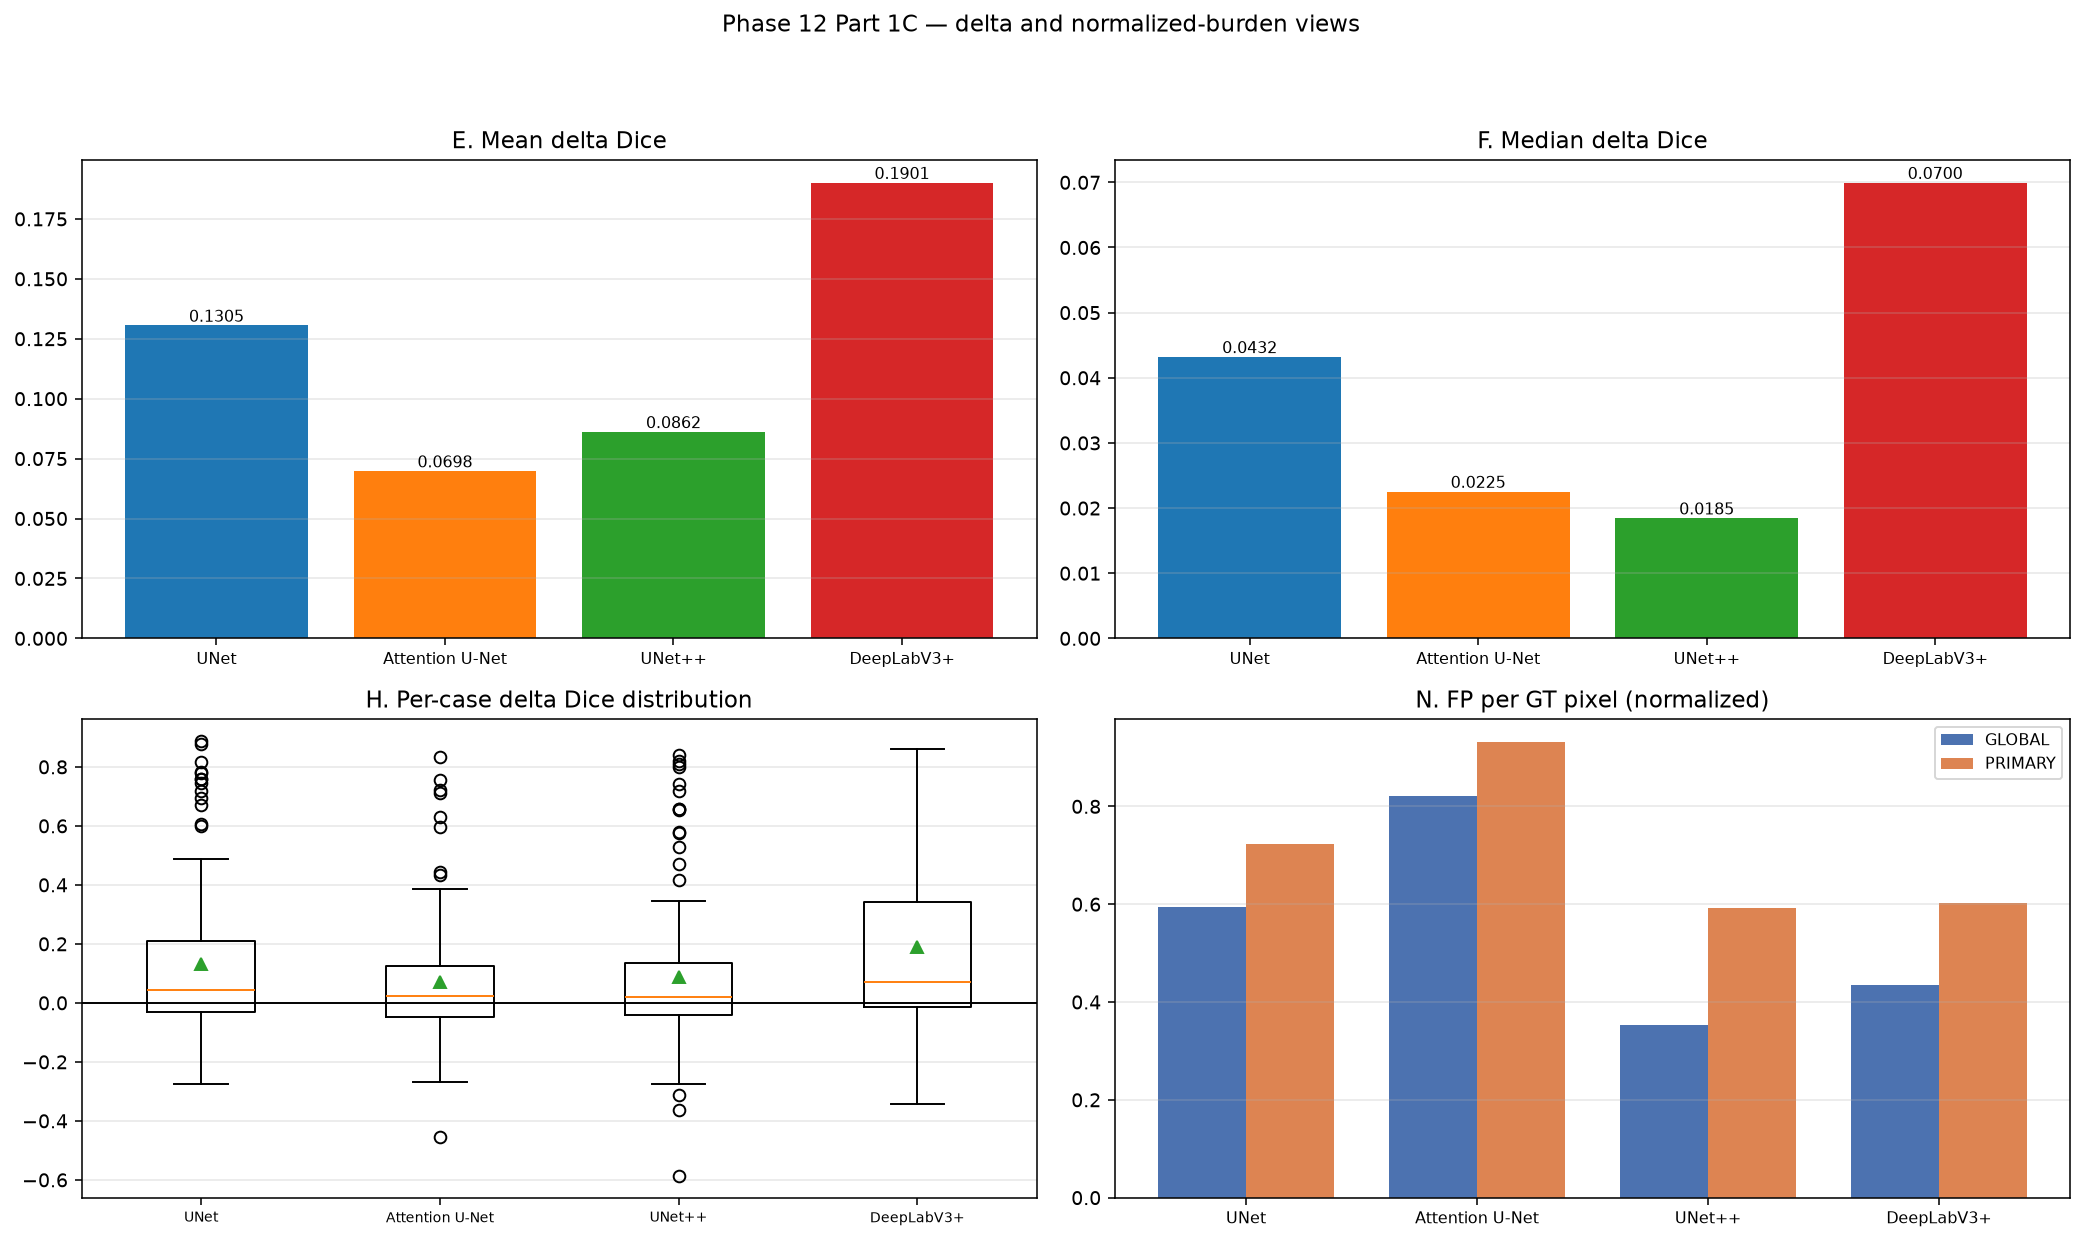

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(15,9))
b=axes[0,0].bar(ORDER, dist['mean_delta_dice'], color=[COLORS[m] for m in ORDER])
for bb in b: axes[0,0].annotate(f'{bb.get_height():.4f}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                               ha='center', va='bottom', fontsize=8)
axes[0,0].set_title('E. Mean delta Dice'); axes[0,0].grid(True, alpha=.3, axis='y')
axes[0,0].tick_params(axis='x', labelsize=8)
b=axes[0,1].bar(ORDER, dist['median_delta_dice'], color=[COLORS[m] for m in ORDER])
for bb in b: axes[0,1].annotate(f'{bb.get_height():.4f}', (bb.get_x()+bb.get_width()/2, bb.get_height()),
                               ha='center', va='bottom', fontsize=8)
axes[0,1].set_title('F. Median delta Dice'); axes[0,1].grid(True, alpha=.3, axis='y')
axes[0,1].tick_params(axis='x', labelsize=8)
data=[delta[delta.model==k]['delta_dice'].values for k in a.MODELS]
axes[1,0].boxplot(data, tick_labels=ORDER, showmeans=True)
axes[1,0].axhline(0, color='black', linewidth=1)
axes[1,0].set_title('H. Per-case delta Dice distribution'); axes[1,0].grid(True, alpha=.3, axis='y')
axes[1,0].tick_params(axis='x', labelsize=7)
nbp = nb.pivot_table(index='model', columns='variant', values='fp_per_gt_pixel_mean')
b1=axes[1,1].bar(x-w/2, [nbp.loc[m,'GLOBAL'] for m in ORDER], w, label='GLOBAL', color='#4c72b0')
b2=axes[1,1].bar(x+w/2, [nbp.loc[m,'PRIMARY'] for m in ORDER], w, label='PRIMARY', color='#dd8452')
axes[1,1].set_xticks(x); axes[1,1].set_xticklabels(ORDER, fontsize=8)
axes[1,1].set_title('N. FP per GT pixel (normalized)'); axes[1,1].legend(fontsize=8)
axes[1,1].grid(True, alpha=.3, axis='y')
fig.suptitle('Phase 12 Part 1C — delta and normalized-burden views', fontsize=12)
plt.tight_layout(rect=[0,0,1,0.94]); p11=FIG/'dashboard_efhn.png'; fig.savefig(p11, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p11)))


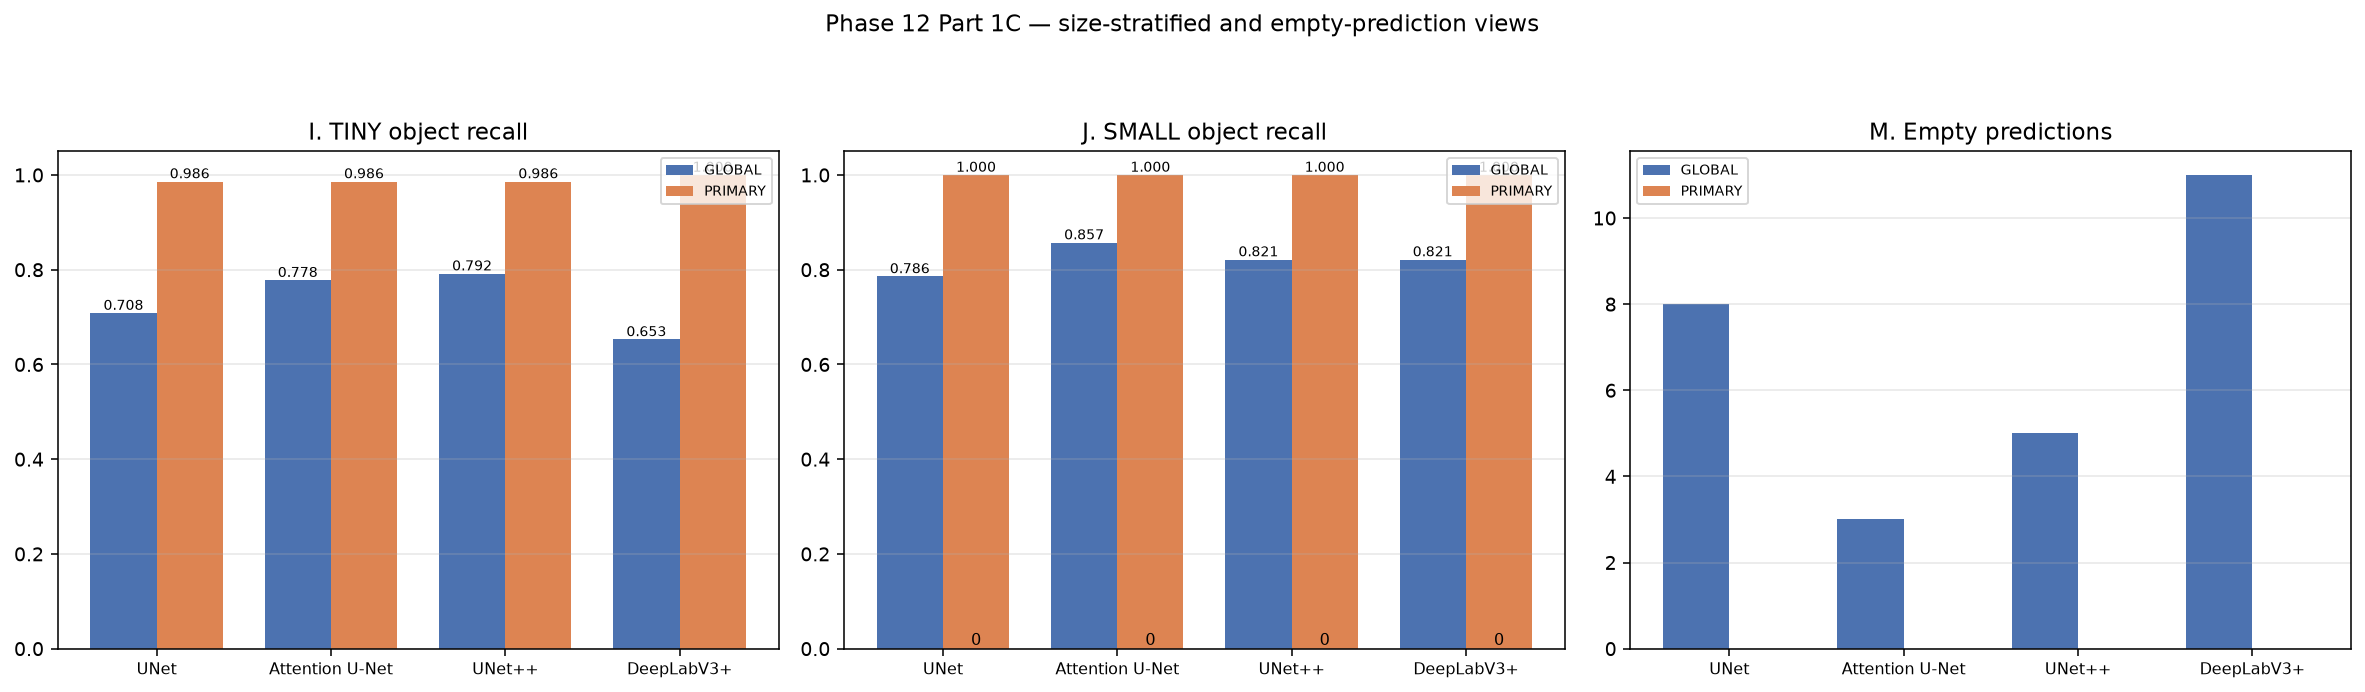

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(17,5))
for ax, s, ttl in [(axes[0],'TINY','I. TINY object recall'), (axes[1],'SMALL','J. SMALL object recall')]:
    d=size[size.size_stratum==s].set_index('model')
    b1=ax.bar(x-w/2, [d.loc[m,'global_object_recall'] for m in ORDER], w, label='GLOBAL', color='#4c72b0')
    b2=ax.bar(x+w/2, [d.loc[m,'primary_object_recall'] for m in ORDER], w, label='PRIMARY', color='#dd8452')
    for bs in (b1,b2):
        for b in bs: ax.annotate(f'{b.get_height():.3f}', (b.get_x()+b.get_width()/2, b.get_height()),
                                 ha='center', va='bottom', fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(ORDER, fontsize=8); ax.set_ylim(0,1.05)
    ax.set_title(ttl); ax.legend(fontsize=7); ax.grid(True, alpha=.3, axis='y')
b1=axes[2].bar(x-w/2, emp['global_empty'], w, label='GLOBAL', color='#4c72b0')
b2=axes[2].bar(x+w/2, emp['primary_empty'], w, label='PRIMARY', color='#dd8452')
for bs in (b1,b2):
    for b in bs: ax.annotate(f'{int(b.get_height())}', (b.get_x()+b.get_width()/2, b.get_height()),
                             ha='center', va='bottom', fontsize=8)
axes[2].set_xticks(x); axes[2].set_xticklabels(ORDER, fontsize=8)
axes[2].set_title('M. Empty predictions'); axes[2].legend(fontsize=7); axes[2].grid(True, alpha=.3, axis='y')
fig.suptitle('Phase 12 Part 1C — size-stratified and empty-prediction views', fontsize=12)
plt.tight_layout(rect=[0,0,1,0.92]); p12=FIG/'dashboard_ijm.png'; fig.savefig(p12, dpi=140, bbox_inches='tight'); plt.close(fig)
display(IPImage(filename=str(p12)))


## 23. Mechanism Evidence Matrix

Status vocabulary is limited to `SUPPORTIVE_DESCRIPTIVE_EVIDENCE` /
`MIXED_DESCRIPTIVE_EVIDENCE` / `NON_SUPPORTIVE_DESCRIPTIVE_EVIDENCE` / `NOT_EVALUABLE`.
**These are NOT combined into a final GO/NO-GO.**


In [33]:
mat = pd.read_csv(T/'phase12_oracle_mechanism_evidence_matrix.csv')
display(mat[['dimension','population','observed_direction','quantitative_summary','status']])
print()
print('status counts:', mat.status.value_counts().to_dict())
print()
print('NO GO / NO_GO / REVISE_LOCALIZER is issued here.')


,dimension,population,observed_direction,quantitative_summary,status
0,paired_dice,FULL_FIELD 103 x 4 models,INCREASE,"mean delta_dice per model: {'attention_unet': 0.0698, 'deeplabv3plus': 0.1901, 'unet': 0.1305, 'unetpp': 0.0862}",SUPPORTIVE_DESCRIPTIVE_EVIDENCE
1,object_recall,FULL_FIELD 103 x 4 models,INCREASE,"mean delta_object_recall per model: {'attention_unet': 0.1408, 'deeplabv3plus': 0.2379, 'unet': 0.2087, 'unetpp': 0.1553}",SUPPORTIVE_DESCRIPTIVE_EVIDENCE
2,component_recovery,152 components x 4 models,INCREASE,total RECOVERED component detections: 120,SUPPORTIVE_DESCRIPTIVE_EVIDENCE
3,TINY_recovery,72 TINY components,INCREASE,"TINY recovered 74, lost 0",SUPPORTIVE_DESCRIPTIVE_EVIDENCE
4,SMALL_recovery,28 SMALL components,INCREASE,"SMALL recovered 20, lost 0",SUPPORTIVE_DESCRIPTIVE_EVIDENCE
5,empty_recovery,global-empty cases,INCREASE,recovered empty cases: 27,SUPPORTIVE_DESCRIPTIVE_EVIDENCE
6,phase11_all_four_low_recovery,12 frozen cases x 4 models,INCREASE,mean delta_dice 0.4857 (per-model means see cohort table),SUPPORTIVE_DESCRIPTIVE_EVIDENCE
7,phase11_hard_case_recovery,frozen hard cohort (10 of 16 in FULL_FIELD) x 4 models,INCREASE,mean delta_dice 0.4948 (aggregated over case-model rows),SUPPORTIVE_DESCRIPTIVE_EVIDENCE
8,worsening_cases,cases with delta_dice < 0,PRESENT,150 case-model rows worsen; max worsening -0.5866,MIXED_DESCRIPTIVE_EVIDENCE
9,fp_precision_cost,FULL_FIELD 103 x 4 models,MIXED,"mean delta_precision {'attention_unet': -0.0117, 'deeplabv3plus': -0.0004, 'unet': -0.0236, 'unetpp': -0.05}",MIXED_DESCRIPTIVE_EVIDENCE



status counts: {'SUPPORTIVE_DESCRIPTIVE_EVIDENCE': 8, 'MIXED_DESCRIPTIVE_EVIDENCE': 5, 'NOT_EVALUABLE': 1}

NO GO / NO_GO / REVISE_LOCALIZER is issued here.


## 24. Limitations

- Single seed; no significance testing; no confidence intervals.
- The primary variant **retains the global prediction outside the oracle region**, so its
  Dice is lower than crop-only by construction — crop-only is not a fair deployable
  comparator.
- **Oracle-constrained FP is artificially advantaged**: the oracle knows where the target is.
- `GLOBAL_NATIVE` is a Phase-12 paired baseline, not a replacement for the authoritative
  Phase-10 EVALUATION_512 VAL metrics.
- HD95 invalid cases are flagged and excluded from HD95 statistics only (never dropped).
- `COMBINED_LEGACY_RESTORE_SENSITIVITY` cannot isolate uint8 quantisation; it is not
  gate-usable.
- Only 103 FULL_FIELD cases; ROI acquisition cases are outside this study.
- Worsening cases are **exhaustively** reported, not cherry-picked.
- No causality is claimed for the ALL_FOUR_LOW response.


## 25–28. Upstream Frozen Training Provenance

Read-only from the frozen Phase-10 normalized epoch tables. **Every epoch row is shown.**


### 225. Upstream Complete Epoch Table — UNet


In [34]:
t = a.load_upstream_epoch_table('unet')
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM UNet ===')
print('  rows:', len(t), '| expected:', a.EXPECTED_EPOCH_ROWS['unet'])
print('  first/last:', min(eps), '/', max(eps), '| missing:', sorted(set(exp)-set(eps)),
      '| duplicates:', sorted({e for e in eps if eps.count(e)>1}))
assert len(t)==a.EXPECTED_EPOCH_ROWS['unet'] and eps==exp
print()
display(t)


=== UPSTREAM UNet ===
  rows: 59 | expected: 59
  first/last: 1 / 59 | missing: [] | duplicates: []



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,1,0.442458,0.465926,0.431176,0.340278,NaN,NaN,0.000100,NaN,1,0,268.742252,BEST_SAVED,NaN,NaN,True,False,0
1,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,2,0.392092,0.396965,0.456776,0.366742,NaN,NaN,0.000100,NaN,1,0,60.102438,BEST_SAVED,0.025599,NaN,True,False,0
2,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,3,0.367363,0.359159,0.490891,0.401569,NaN,NaN,0.000100,NaN,1,0,60.311679,BEST_SAVED,0.034116,NaN,True,False,0
3,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,4,0.351135,0.425429,0.497879,0.397826,NaN,NaN,0.000100,NaN,1,0,60.858533,BEST_SAVED,0.006987,NaN,True,False,0
4,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,5,0.335718,0.332848,0.530259,0.438920,NaN,NaN,0.000099,NaN,1,0,63.602900,BEST_SAVED,0.032380,NaN,True,False,0
5,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,6,0.321234,0.321200,0.545095,0.452030,NaN,NaN,0.000099,NaN,1,0,63.525723,BEST_SAVED,0.014836,NaN,True,False,0
6,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,7,0.306985,0.305672,0.579637,0.472824,NaN,NaN,0.000099,NaN,1,0,64.249523,BEST_SAVED,0.034542,NaN,True,False,0
7,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,8,0.292267,0.391134,0.563304,0.445191,NaN,NaN,0.000098,NaN,0,1,63.671509,LATEST_ONLY,-0.016333,NaN,False,False,1
8,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,9,0.272067,0.287922,0.638627,0.520392,NaN,NaN,0.000098,NaN,1,0,63.566675,BEST_SAVED,0.075323,NaN,True,False,0
9,UNet,phase9_kub_unet_baseline_seed42_512_clean_v3,10,0.261210,0.260292,0.654405,0.541183,NaN,NaN,0.000098,NaN,1,0,63.609702,BEST_SAVED,0.015778,NaN,True,False,0


### 226. Upstream Complete Epoch Table — Attention U-Net


In [35]:
t = a.load_upstream_epoch_table('attention_unet')
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM Attention U-Net ===')
print('  rows:', len(t), '| expected:', a.EXPECTED_EPOCH_ROWS['attention_unet'])
print('  first/last:', min(eps), '/', max(eps), '| missing:', sorted(set(exp)-set(eps)),
      '| duplicates:', sorted({e for e in eps if eps.count(e)>1}))
assert len(t)==a.EXPECTED_EPOCH_ROWS['attention_unet'] and eps==exp
print()
display(t)


=== UPSTREAM Attention U-Net ===
  rows: 69 | expected: 69
  first/last: 1 / 69 | missing: [] | duplicates: []



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,1,0.511852,0.492498,0.455501,0.364793,0.557557,0.601329,0.000100,0.455501,1,0,180.8,BEST_SAVED,NaN,NaN,True,False,0
1,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,2,0.421238,0.414937,0.453676,0.365484,0.583015,0.572629,0.000100,0.455501,0,1,73.8,LATEST_ONLY,-0.001825,0.000000,False,False,1
2,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,3,0.385591,0.402041,0.469479,0.383368,0.685439,0.592345,0.000100,0.469479,1,0,70.7,BEST_SAVED,0.015802,0.013977,True,False,0
3,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,4,0.363607,0.365701,0.492169,0.400162,0.595332,0.512817,0.000100,0.492169,1,0,70.3,BEST_SAVED,0.022690,0.022690,True,False,0
4,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,5,0.347567,0.357465,0.507544,0.418799,0.459013,0.673806,0.000099,0.507544,1,0,73.2,BEST_SAVED,0.015375,0.015375,True,False,0
5,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,6,0.335710,0.337032,0.542214,0.445455,0.538902,0.645993,0.000099,0.542214,1,0,73.1,BEST_SAVED,0.034670,0.034670,True,False,0
6,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,7,0.326942,0.326772,0.546270,0.452797,0.531451,0.653997,0.000099,0.546270,1,0,73.4,BEST_SAVED,0.004056,0.004056,True,False,0
7,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,8,0.313945,0.307033,0.566118,0.473826,0.656369,0.611473,0.000098,0.566118,1,0,74.5,BEST_SAVED,0.019848,0.019848,True,False,0
8,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,9,0.299837,0.293197,0.603426,0.499475,0.653554,0.661779,0.000098,0.603426,1,0,74.2,BEST_SAVED,0.037307,0.037307,True,False,0
9,Attention U-Net,phase10_kub_attention_unet_seed42_512_clean_v3,10,0.285437,0.288194,0.604399,0.499341,0.690762,0.631612,0.000098,0.604399,1,0,74.3,BEST_SAVED,0.000973,0.000973,True,False,0


### 227. Upstream Complete Epoch Table — UNet++


In [36]:
t = a.load_upstream_epoch_table('unetpp')
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM UNet++ ===')
print('  rows:', len(t), '| expected:', a.EXPECTED_EPOCH_ROWS['unetpp'])
print('  first/last:', min(eps), '/', max(eps), '| missing:', sorted(set(exp)-set(eps)),
      '| duplicates:', sorted({e for e in eps if eps.count(e)>1}))
assert len(t)==a.EXPECTED_EPOCH_ROWS['unetpp'] and eps==exp
print()
display(t)


=== UPSTREAM UNet++ ===
  rows: 85 | expected: 85
  first/last: 1 / 85 | missing: [] | duplicates: []



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,1,0.438780,0.416830,0.454545,0.363090,0.678880,0.502299,0.000100,0.454545,1,0,290.9,BEST_SAVED,NaN,NaN,True,False,0
1,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,2,0.388098,0.421986,0.468632,0.378370,0.704706,0.592291,0.000100,0.468632,1,0,180.4,BEST_SAVED,0.014087,0.014087,True,False,0
2,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,3,0.363468,0.443350,0.465154,0.372904,0.571621,0.639822,0.000100,0.468632,0,1,180.6,LATEST_ONLY,-0.003477,0.000000,False,False,1
3,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,4,0.352005,0.348390,0.519276,0.427362,0.499869,0.639654,0.000100,0.519276,1,0,180.6,BEST_SAVED,0.054121,0.050644,True,False,0
4,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,5,0.336932,0.323569,0.554764,0.460919,0.562959,0.635015,0.000099,0.554764,1,0,178.6,BEST_SAVED,0.035489,0.035489,True,False,0
5,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,6,0.325398,0.328325,0.562319,0.462126,0.589963,0.666141,0.000099,0.562319,1,0,178.7,BEST_SAVED,0.007554,0.007554,True,False,0
6,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,7,0.310921,0.328777,0.551526,0.443353,0.545447,0.666942,0.000099,0.562319,0,1,178.6,LATEST_ONLY,-0.010793,0.000000,False,False,1
7,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,8,0.297655,0.320062,0.547991,0.450617,0.499140,0.808599,0.000098,0.562319,0,2,178.9,LATEST_ONLY,-0.003535,0.000000,False,False,2
8,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,9,0.265427,0.276223,0.620099,0.504560,0.570966,0.801323,0.000098,0.620099,1,0,178.9,BEST_SAVED,0.072109,0.057781,True,False,0
9,UNet++,phase10_kub_unetpp_seed42_512_clean_v3,10,0.258951,0.272386,0.659271,0.536225,0.616674,0.808719,0.000098,0.659271,1,0,179.0,BEST_SAVED,0.039172,0.039172,True,False,0


### 228. Upstream Complete Epoch Table — DeepLabV3+


In [37]:
t = a.load_upstream_epoch_table('deeplabv3plus')
eps = t['epoch'].astype(int).tolist(); exp = list(range(1, len(t)+1))
print('=== UPSTREAM DeepLabV3+ ===')
print('  rows:', len(t), '| expected:', a.EXPECTED_EPOCH_ROWS['deeplabv3plus'])
print('  first/last:', min(eps), '/', max(eps), '| missing:', sorted(set(exp)-set(eps)),
      '| duplicates:', sorted({e for e in eps if eps.count(e)>1}))
assert len(t)==a.EXPECTED_EPOCH_ROWS['deeplabv3plus'] and eps==exp
print()
display(t)


=== UPSTREAM DeepLabV3+ ===
  rows: 67 | expected: 67
  first/last: 1 / 67 | missing: [] | duplicates: []



,model,experiment_id,epoch,train_loss,val_loss,val_macro_dice,val_macro_iou,val_precision,val_recall,learning_rate,best_metric_so_far,improved,bad_epochs,elapsed_seconds,checkpoint_event,delta_val_dice_vs_previous_epoch,delta_best_metric,is_new_best,is_best_epoch,epochs_since_best
0,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,1,0.377359,0.349518,0.487975,0.407391,0.870639,0.504660,0.000100,0.487975,1,0,188.1,BEST_SAVED,NaN,NaN,True,False,0
1,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,2,0.330579,0.314964,0.540444,0.460717,0.769889,0.578849,0.000100,0.540444,1,0,74.1,BEST_SAVED,0.052469,0.052469,True,False,0
2,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,3,0.307240,0.299174,0.563059,0.480463,0.749197,0.596709,0.000100,0.563059,1,0,73.8,BEST_SAVED,0.022615,0.022615,True,False,0
3,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,4,0.287705,0.291801,0.574313,0.487857,0.736589,0.615886,0.000100,0.574313,1,0,74.1,BEST_SAVED,0.011254,0.011254,True,False,0
4,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,5,0.273234,0.300474,0.571880,0.480890,0.696173,0.606999,0.000099,0.574313,0,1,73.4,LATEST_ONLY,-0.002432,0.000000,False,False,1
5,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,6,0.261933,0.269859,0.602290,0.513627,0.702040,0.631256,0.000099,0.602290,1,0,73.4,BEST_SAVED,0.030410,0.027978,True,False,0
6,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,7,0.246003,0.270271,0.610485,0.516051,0.617278,0.741697,0.000099,0.610485,1,0,73.3,BEST_SAVED,0.008194,0.008194,True,False,0
7,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,8,0.233239,0.248815,0.645464,0.541690,0.721210,0.702844,0.000098,0.645464,1,0,74.8,BEST_SAVED,0.034979,0.034979,True,False,0
8,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,9,0.221540,0.234570,0.669442,0.563907,0.757588,0.721188,0.000098,0.669442,1,0,73.4,BEST_SAVED,0.023978,0.023978,True,False,0
9,DeepLabV3+,phase10_kub_deeplabv3plus_seed42_512_clean_v3,10,0.213646,0.225732,0.683498,0.576951,0.709659,0.729663,0.000098,0.683498,1,0,73.2,BEST_SAVED,0.014057,0.014057,True,False,0


## 29. Artifact Registry


In [38]:
import hashlib
def _sh(rel):
    q = PROJECT_ROOT/rel
    return hashlib.sha256(q.read_bytes()).hexdigest() if q.exists() else 'N/A'
names = [
 'phase12_primary_global_vs_oracle_summary.csv','phase12_primary_delta_distribution_by_model.csv',
 'phase12_primary_worsened_cases.csv','phase12_primary_worsened_summary.csv',
 'phase12_primary_benefit_cost_summary.csv','phase12_primary_normalized_error_burden.csv',
 'phase12_primary_size_stratified_component_recovery.csv','phase12_primary_component_recovery_events.csv',
 'phase12_primary_multicomponent_outcomes.csv','phase12_primary_multicomponent_transitions.csv',
 'phase12_primary_empty_prediction_recovery.csv','phase12_primary_empty_prediction_ids.csv',
 'phase12_primary_hd95_analysis.csv','phase12_phase11_frozen_cohort_oracle_response.csv',
 'phase12_primary_category_analysis.csv','phase12_primary_vs_crop_only_comparator.csv',
 'phase12_cross_architecture_oracle_consistency.csv','phase12_cross_architecture_distribution.csv',
 'phase12_all_four_low_oracle_response.csv','phase12_oracle_mechanism_evidence_matrix.csv',
]
rows=[{'artifact':n,'type':'table','path':f'reports/tables/{n}','sha256':_sh(f'reports/tables/{n}')} for n in names]
rows.append({'artifact':'phase12_part1b_analysis_errata.md','type':'audit',
             'path':'reports/audits/phase12_part1b_analysis_errata.md',
             'sha256':_sh('reports/audits/phase12_part1b_analysis_errata.md')})
for pth in [p1,p2,p3,p4,p5,p6,p7,p8,p9,p10,p11,p12]:
    rows.append({'artifact':pth.name,'type':'figure',
                 'path':f'reports/figures/phase12_clean_v3_oracle_analysis/{pth.name}',
                 'sha256':_sh(f'reports/figures/phase12_clean_v3_oracle_analysis/{pth.name}')})
rows.append({'artifact':'phase12_oracle_analysis.py','type':'support_code',
             'path':'notebooks/phasewise/phase_12_oracle_roi/code/phase12_oracle_analysis.py',
             'sha256':_sh('notebooks/phasewise/phase_12_oracle_roi/code/phase12_oracle_analysis.py')})
REG = pd.DataFrame(rows)
rp = T/'phase12_part1c_artifact_registry.csv'; REG.to_csv(rp, index=False)
print('registry:', rp.name, len(REG), 'entries')
display(REG)


registry: phase12_part1c_artifact_registry.csv 34 entries


,artifact,type,path,sha256
0,phase12_primary_global_vs_oracle_summary.csv,table,reports/tables/phase12_primary_global_vs_oracle_summary.csv,c8e363bedb9fff5b1c48d753bb6d03549602f606ac8e8959686178d00a7ab5a1
1,phase12_primary_delta_distribution_by_model.csv,table,reports/tables/phase12_primary_delta_distribution_by_model.csv,6815e4d782dd30473b4a476668df65100de5d3e1931eb2cfed3f43eac59f0a8d
2,phase12_primary_worsened_cases.csv,table,reports/tables/phase12_primary_worsened_cases.csv,a1127c748b2c1c48d2976bab6af5ab6a76691630add6310a9735b814d4140d90
3,phase12_primary_worsened_summary.csv,table,reports/tables/phase12_primary_worsened_summary.csv,8d29971909626a583c3bb4c0d040533ed943761c6447a18cac68347b16099bcb
4,phase12_primary_benefit_cost_summary.csv,table,reports/tables/phase12_primary_benefit_cost_summary.csv,dafbbeb43a4da1d2894a8567ede9dabcd600278900d948820acf4319de2dc51a
5,phase12_primary_normalized_error_burden.csv,table,reports/tables/phase12_primary_normalized_error_burden.csv,05760daee2a3f673c1d3749103d6e027385a5caf9f966f672561387a8cab8414
6,phase12_primary_size_stratified_component_recovery.csv,table,reports/tables/phase12_primary_size_stratified_component_recovery.csv,1366d35603ee9902a88560fa4740a85ae39c671c483f84e7dc1308224eab0d58
7,phase12_primary_component_recovery_events.csv,table,reports/tables/phase12_primary_component_recovery_events.csv,3b3aa395d6e3b502cbfcbc80e4984ac67a05e5478ef2dd786dfa715f47b8ec6b
8,phase12_primary_multicomponent_outcomes.csv,table,reports/tables/phase12_primary_multicomponent_outcomes.csv,e9d770e6ae2d04c730d15d921e3cfde696f063d9f673831d433909edc9d86541
9,phase12_primary_multicomponent_transitions.csv,table,reports/tables/phase12_primary_multicomponent_transitions.csv,20c77c8e393c343efa45db920151e4357fdff059fc001a6db08b6c673696cfc9


## 30. Supervisor-Decision Boundary


In [39]:
print('=== PHASE-12 PART-1C BOUNDARY ===')
print('Model loading        : 0')
print('Inference passes     : 0')
print('Training epochs      : 0')
print('Optimizer steps      : 0')
print('Source tables modified: 0')
print('Statistical testing  : NONE')
print('Winner / rank        : NONE')
print('TEST reads           : 0')
print()
print('FINAL PHASE-12 CONCLUSION: NOT ISSUED')
print('REGIONAL INTEGRATION GATE DECISION: NOT YET')
print('PART-1C STATUS: READY_FOR_SUPERVISOR_PHASE12_MECHANISM_CONCLUSION')
print()
print('NEXT: WAIT_FOR_SUPERVISOR_PHASE12_MECHANISM_CONCLUSION')


=== PHASE-12 PART-1C BOUNDARY ===


Model loading        : 0
Inference passes     : 0
Training epochs      : 0
Optimizer steps      : 0
Source tables modified: 0
Statistical testing  : NONE
Winner / rank        : NONE
TEST reads           : 0

FINAL PHASE-12 CONCLUSION: NOT ISSUED
REGIONAL INTEGRATION GATE DECISION: NOT YET
PART-1C STATUS: READY_FOR_SUPERVISOR_PHASE12_MECHANISM_CONCLUSION

NEXT: WAIT_FOR_SUPERVISOR_PHASE12_MECHANISM_CONCLUSION


## Descriptive Evaluation and Visual Evidence — Phase 12 (oracle ROI upper bound)

**Metric source / provenance.** Central post-audit arms `GLOBAL` (= Phase-10
UNet++) and `ORACLE_REGIONAL` (GT-bbox proposals + frozen Phase-14 refiner), plus
the saved Phase-12 primary tables. No inference was performed in this notebook.

**Metric-domain label.** `PIXEL_SEGMENTATION` + `OBJECT_COMPONENT_DETECTION`.
Post-hoc added values are `DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE`;
the GLOBAL↔ORACLE paired difference is `DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT`.

**Interpretation guard.** ORACLE_REGIONAL is a **diagnostic upper bound** obtained
from ground-truth bounding boxes. It is **not deployable performance** and must
never be reported as a method result.

**What this section does NOT prove.** It bounds what a perfect ROI supply could
buy; it does not show that any GT-free method attains it.

,artifact,sha256
0,project_evaluation_segmentation_summary.csv,d7cda533740600f4
1,project_evaluation_confusion_matrices.json,64c32e8e858eac8d
2,project_evaluation_paired_comparisons.csv,d21254793973b1ed
3,phase12_primary_global_vs_oracle_summary.csv,c8e363bedb9fff5b


,arm,pooled_dice,pooled_iou,pooled_precision,pooled_recall,pooled_specificity,pooled_balanced_accuracy,pooled_mcc,image_mean_hd95,image_mean_surface_dice,brier,ece,roc_auc,dice_ci_low,dice_ci_high
0,GLOBAL,0.665747,0.498966,0.790486,0.575010,0.999883,0.787446,0.673986,332.727336,0.350720,0.000401,0.000369,0.827385,0.581571,0.686591
1,ORACLE_REGIONAL,0.751746,0.602238,0.821843,0.692666,0.999885,0.846276,0.754325,266.780822,0.502613,0.000291,0.000220,0.972221,0.776504,0.825454


,arm,size_stratum,gt_components,detected,detection_recall,metric_domain
0,GLOBAL,TINY,72,57,0.791667,COMPONENT_DETECTION
1,GLOBAL,SMALL,28,23,0.821429,COMPONENT_DETECTION
2,GLOBAL,MEDIUM,36,31,0.861111,COMPONENT_DETECTION
3,GLOBAL,LARGE,16,14,0.875000,COMPONENT_DETECTION
4,ORACLE_REGIONAL,TINY,72,72,1.000000,COMPONENT_DETECTION
5,ORACLE_REGIONAL,SMALL,28,28,1.000000,COMPONENT_DETECTION
6,ORACLE_REGIONAL,MEDIUM,36,36,1.000000,COMPONENT_DETECTION
7,ORACLE_REGIONAL,LARGE,16,16,1.000000,COMPONENT_DETECTION


,comparison,metric,n_pairs,mean_difference,ci_low,ci_high,wilcoxon_p,label
3,ORACLE_REGIONAL - GLOBAL,dice,103,0.166499,0.124279,0.213573,3.034700e-17,DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


C:\Users\user\AppData\Local\Temp\ipykernel_29564\3288594001.py:70: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p, 900)


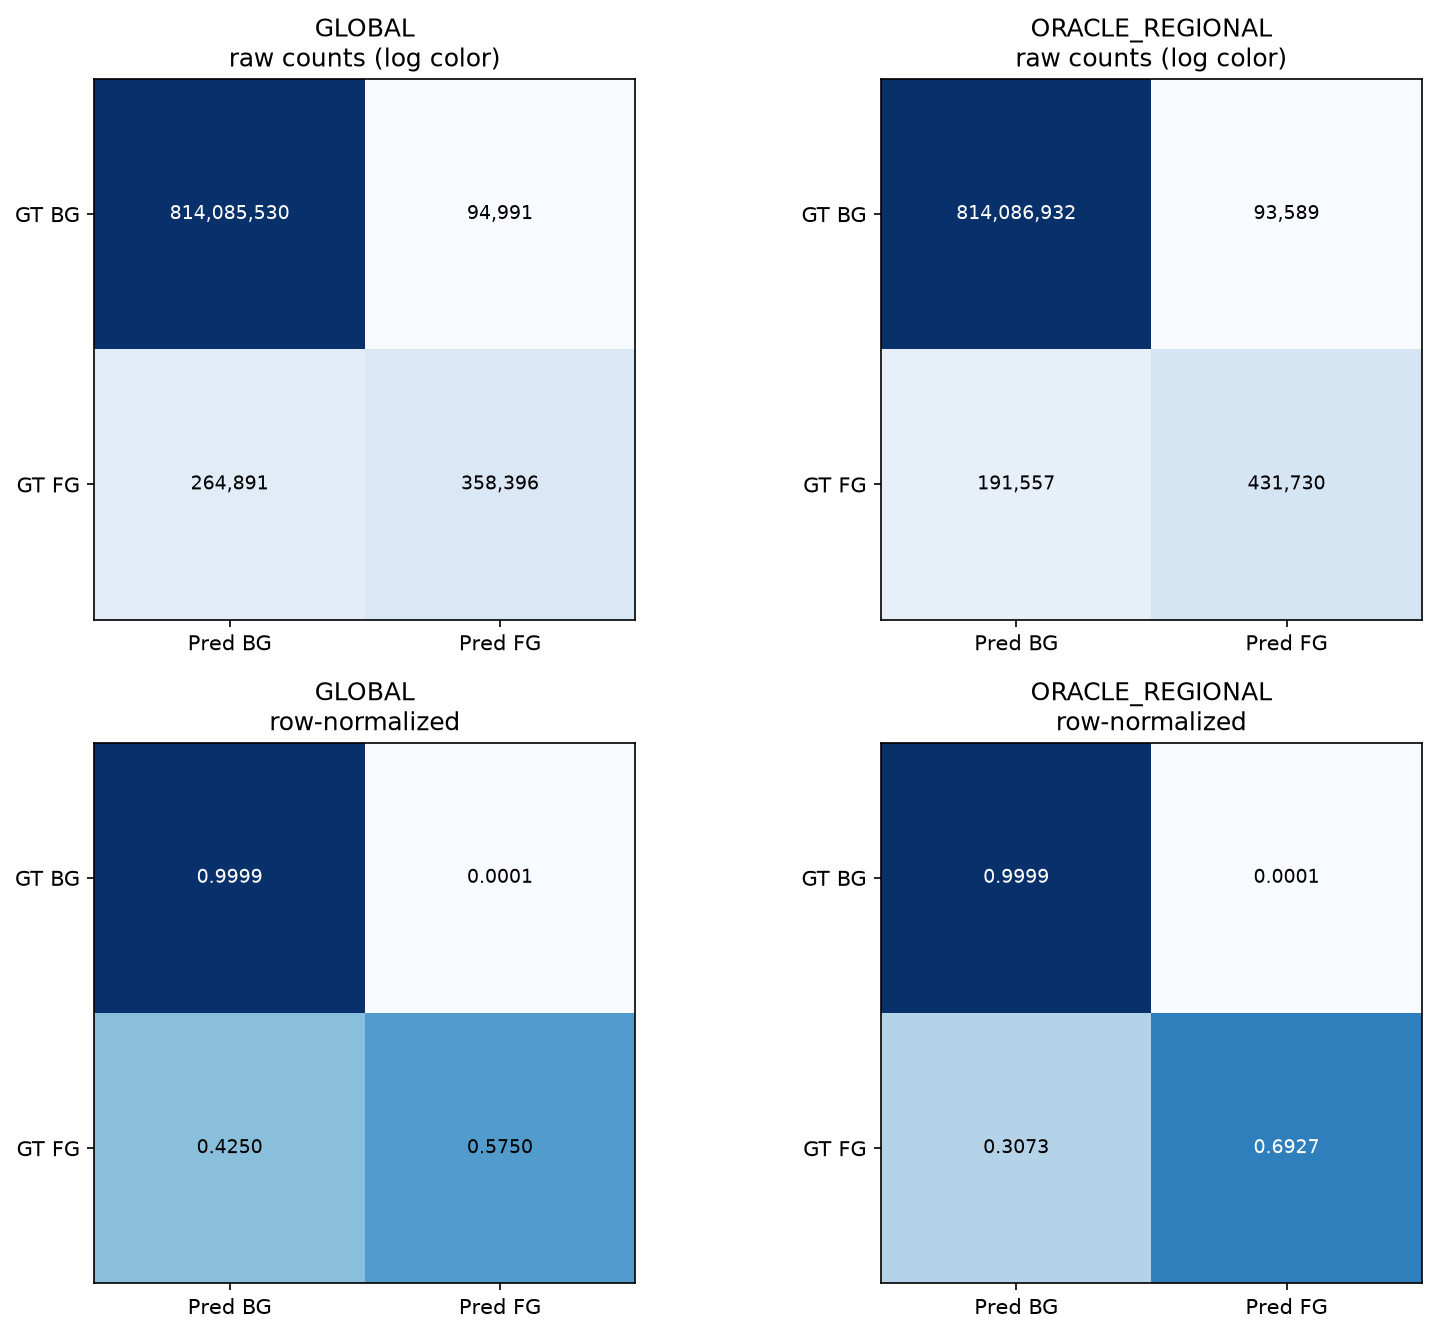

C:\Users\user\AppData\Local\Temp\ipykernel_29564\3288594001.py:84: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)


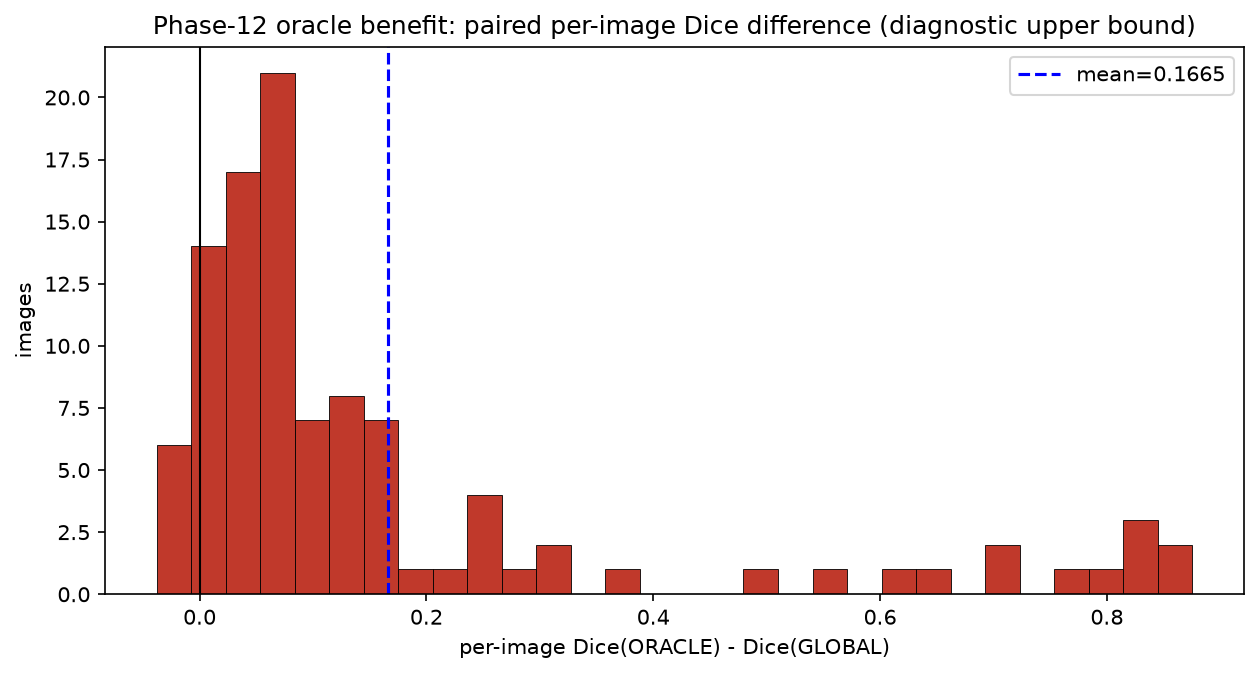

ORACLE_REGIONAL is a DIAGNOSTIC UPPER BOUND, not deployable performance.
All values above are DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE | paired difference is DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT


In [40]:
# ── Phasewise evaluation / visualization synchronization (post-audit) ─────────
import json as _json, hashlib as _hashlib
from pathlib import Path as _Path
import numpy as _np
import pandas as _pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as _plt
try:
    from IPython.display import display as _disp, Image as _Img
except Exception:
    _disp = print; _Img = None
_ROOT = _Path('D:/Softfors/jup')
_AUD = _ROOT / 'reports' / 'audits'
_TAB = _ROOT / 'reports' / 'tables'
_FIG = _ROOT / 'reports' / 'figures' / 'phasewise_sync'
_FIG.mkdir(parents=True, exist_ok=True)
def _sha(p): return _hashlib.sha256(_Path(p).read_bytes()).hexdigest()
def _load(p): return _json.loads(_Path(p).read_text(encoding='utf-8'))
def _show(p, w=840):
    if _Img is not None and _Path(p).exists():
        _disp(_Img(filename=str(p), width=w))
LBL      = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_PROSPECTIVE_GATE'
LBL_H3   = 'DESCRIPTIVE_SUPPORTING_METRIC__NOT_H3_GATE'
LBL_STAT = 'DESCRIPTIVE_POST_HOC_STATISTICAL_SUPPORT'

prov = [
    ('project_evaluation_segmentation_summary.csv', _TAB / 'project_evaluation_segmentation_summary.csv'),
    ('project_evaluation_confusion_matrices.json', _TAB / 'project_evaluation_confusion_matrices.json'),
    ('project_evaluation_paired_comparisons.csv', _TAB / 'project_evaluation_paired_comparisons.csv'),
    ('phase12_primary_global_vs_oracle_summary.csv', _TAB / 'phase12_primary_global_vs_oracle_summary.csv'),
]
_disp(_pd.DataFrame([{'artifact': n, 'sha256': _sha(p)[:16]} for n, p in prov if p.exists()]))

summ = _pd.read_csv(_TAB / 'project_evaluation_segmentation_summary.csv')
sub = summ[summ['arm'].isin(['GLOBAL', 'ORACLE_REGIONAL'])]
cols = ['arm', 'pooled_dice', 'pooled_iou', 'pooled_precision', 'pooled_recall', 'pooled_specificity',
        'pooled_balanced_accuracy', 'pooled_mcc', 'image_mean_hd95', 'image_mean_surface_dice',
        'brier', 'ece', 'roc_auc', 'dice_ci_low', 'dice_ci_high']
_disp(sub[cols].round(6))

size = _pd.read_csv(_TAB / 'project_evaluation_component_recall_by_size.csv')
_disp(size[size['arm'].isin(['GLOBAL', 'ORACLE_REGIONAL'])])

pc = _pd.read_csv(_TAB / 'project_evaluation_paired_comparisons.csv')
_disp(pc[pc['comparison'].str.contains('ORACLE')][['comparison', 'metric', 'n_pairs', 'mean_difference', 'ci_low', 'ci_high', 'wilcoxon_p', 'label']])

conf = _load(_TAB / 'project_evaluation_confusion_matrices.json')
fig, axes = _plt.subplots(2, 2, figsize=(11, 9))
for j, arm in enumerate(['GLOBAL', 'ORACLE_REGIONAL']):
    d = conf[arm]
    raw = _np.array(d['matrix_raw'], dtype=float); nrm = _np.array(d['matrix_row_normalized'], dtype=float)
    axes[0, j].imshow(_np.log10(raw + 1), cmap='Blues')
    for a in range(2):
        for b in range(2):
            axes[0, j].text(b, a, f'{int(raw[a, b]):,}', ha='center', va='center', fontsize=9,
                            color='black' if raw[a, b] < raw.max() * 0.6 else 'white')
    axes[0, j].set_xticks([0, 1]); axes[0, j].set_xticklabels(['Pred BG', 'Pred FG'])
    axes[0, j].set_yticks([0, 1]); axes[0, j].set_yticklabels(['GT BG', 'GT FG'])
    axes[0, j].set_title(f'{arm}\nraw counts (log color)')
    axes[1, j].imshow(nrm, cmap='Blues', vmin=0, vmax=1)
    for a in range(2):
        for b in range(2):
            axes[1, j].text(b, a, f'{nrm[a, b]:.4f}', ha='center', va='center', fontsize=9,
                            color='black' if nrm[a, b] < 0.6 else 'white')
    axes[1, j].set_xticks([0, 1]); axes[1, j].set_xticklabels(['Pred BG', 'Pred FG'])
    axes[1, j].set_yticks([0, 1]); axes[1, j].set_yticklabels(['GT BG', 'GT FG'])
    axes[1, j].set_title(f'{arm}\nrow-normalized')
_plt.tight_layout(); _p = _FIG / 'phase12_confusion_global_vs_oracle.png'
_plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p, 900)

pi = _pd.read_csv(_TAB / 'project_evaluation_per_image_metrics.csv')
piv = pi.pivot_table(index='sample_id', columns='arm', values='dice')
if 'GLOBAL' in piv and 'ORACLE_REGIONAL' in piv:
    d = (piv['ORACLE_REGIONAL'] - piv['GLOBAL']).astype(float)
    fig, ax = _plt.subplots(figsize=(8.5, 4.6))
    ax.hist(d, bins=30, color='#c0392b', edgecolor='black', lw=0.4)
    ax.axvline(0, color='black', lw=1)
    ax.axvline(float(d.mean()), color='blue', ls='--', label=f'mean={d.mean():.4f}')
    ax.set_xlabel('per-image Dice(ORACLE) - Dice(GLOBAL)'); ax.set_ylabel('images')
    ax.set_title('Phase-12 oracle benefit: paired per-image Dice difference (diagnostic upper bound)')
    ax.legend()
    _plt.tight_layout(); _p = _FIG / 'phase12_paired_oracle_benefit.png'
    _plt.savefig(str(_p), dpi=150, bbox_inches='tight'); _plt.show(); _show(_p)

print('ORACLE_REGIONAL is a DIAGNOSTIC UPPER BOUND, not deployable performance.')
print('All values above are', LBL, '| paired difference is', LBL_STAT)